# Stage 10 — Interpretation and Mechanistic Explanation

Single unified notebook for the final ExtraTrees and CatBoost models.

**Scope**
- Fixed 250 Stage-05 features only (no reselection, no full feature pool).
- **SHAP values are recomputed here (Section 3) from the current fitted Stage-08 models** with TreeSHAP; nothing is retrained or retuned. Before any interpretation the notebook checks that each loaded model reproduces the saved Stage-08 locked-test predictions and that the SHAP values are additive, so tables from an earlier fit cannot be used silently. The refreshed SHAP tables are saved under `outputs/10_interpretation/shap_values/` and also overwrite the legacy `outputs/10_shap_interpretation/tables/` files.
- Example selection uses predicted pIC50 only; observed pIC50 is shown for reporting.
- SVR is excluded (kernel cost).
- Emphasis on environment-aware Morgan mapping, **occurrence-specific SMARTS for the SHAP-highlighted Morgan environments (Section 9, formerly Notebook 16)**, pharmacophore-style grouping of bit environments, error-by-similarity analysis, and lightweight counterfactuals.

All main figures are saved at 600 dpi (PNG) plus SVG; the per-environment SMARTS panels are 300 dpi PNG. Outputs live under `outputs/10_interpretation/`.

In [1]:
# 1. Project setup and imports
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the BRD4 QSAR project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import hashlib
import json
import re
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, SVG, Image as IPyImage
import joblib
import shap
from rdkit import Chem, rdBase
from rdkit.Chem import rdFingerprintGenerator, DataStructs, Draw, rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image, ImageDraw, ImageFont
from io import BytesIO
import xml.etree.ElementTree as ET

from src.utils import OUTPUTS, load_config, write_manifest, setup_plotting

MODELS = ["ExtraTreesRegressor", "CatBoostRegressor"]
MODEL_SHORT = {
    "ExtraTreesRegressor": "ExtraTrees",
    "CatBoostRegressor": "CatBoost",
}

OUT_DIR = OUTPUTS / "10_interpretation"
TABLE_DIR = OUT_DIR / "tables"
FIGURE_DIR = OUT_DIR / "figures"
MOL_DIR = OUT_DIR / "molecular_highlights"
for folder in (TABLE_DIR, FIGURE_DIR, MOL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

setup_plotting()
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600

print(f"Project: {PROJECT_ROOT}")
print(f"Output folder: {OUT_DIR}")
print("Models:", MODELS)

Project: c:\Users\USER\Documents\E\Code
Output folder: C:\Users\USER\Documents\E\Code\outputs\10_interpretation
Models: ['ExtraTreesRegressor', 'CatBoostRegressor']


In [2]:
# 2. Load configuration and required inputs; strict validation
cfg = load_config()
FP_SIZE = int(cfg.get("fingerprint_bits", 2048))
FP_RADIUS = int(cfg.get("fingerprint_radius", 2))
USE_CHIRALITY = bool(cfg.get("use_chirality", True))
SEED = int(cfg.get("seed", 42))

MORGAN = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_SIZE,
    includeChirality=USE_CHIRALITY,
)

SELECTED_FILE = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
TRAIN_IDS_FILE = OUTPUTS / "04_train_test_split/tables/train_ids.csv"
CLEANED_FILE = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
FEATURES_FILE = OUTPUTS / "03_feature_generation/tables/all_features.parquet"
PREDICTIONS_FILE = OUTPUTS / "08_final_model_evaluation/tables/locked_test_predictions_all_models.csv"
AD_FILE = OUTPUTS / "08_final_model_evaluation/tables/applicability_domain_error.csv"
LEGACY_SHAP_DIR = OUTPUTS / "10_shap_interpretation"   # older location; refreshed in Section 3
MODEL_DIR = OUTPUTS / "08_final_model_evaluation/models"
MODEL_FILES = {m: MODEL_DIR / f"final_{m}.joblib" for m in MODELS}

required = [
    SELECTED_FILE, TEST_IDS_FILE, TRAIN_IDS_FILE, CLEANED_FILE,
    FEATURES_FILE, PREDICTIONS_FILE, AD_FILE,
]
required += list(MODEL_FILES.values())   # fitted Stage-08 models; SHAP is recomputed from these
missing = [p for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing prerequisite output(s):\n" + "\n".join(map(str, missing))
        + "\nRun Stages 02–05 and 08 first."
    )

# Fixed 250 features
selected_features = pd.read_csv(SELECTED_FILE)["feature"].astype(str).tolist()
if len(selected_features) != 250 or len(set(selected_features)) != 250:
    raise ValueError(f"Expected exactly 250 unique Stage 05 features; found {len(selected_features)}.")

morgan_features = [f for f in selected_features if f.startswith("ecfp4_")]
descriptor_features = [f for f in selected_features if not f.startswith("ecfp4_")]
print(f"Fixed Stage 05 features: {len(selected_features)}")
print(f"  Morgan bits: {len(morgan_features)}")
print(f"  Non-Morgan descriptors: {len(descriptor_features)}")

# Locked test IDs and structures
test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
test_ids["chembl_id"] = test_ids.chembl_id.astype(str)
if test_ids.chembl_id.duplicated().any():
    raise ValueError("Duplicate IDs in locked test ID file.")

structures = pd.read_csv(
    CLEANED_FILE,
    usecols=["chembl_id", "canonical_smiles"],
    dtype={"chembl_id": str},
)
structures["chembl_id"] = structures.chembl_id.astype(str)
smiles_by_id = structures.set_index("chembl_id").canonical_smiles
if set(test_ids.chembl_id) - set(smiles_by_id.index):
    raise ValueError("Some test molecules lack canonical SMILES.")

# Predictions (ExtraTrees + CatBoost only)
predictions = pd.read_csv(PREDICTIONS_FILE, dtype={"chembl_id": str})
predictions["chembl_id"] = predictions.chembl_id.astype(str)
predictions = predictions.loc[predictions.model.isin(MODELS)].copy()
required_cols = {"model", "chembl_id", "predicted_pIC50", "observed_pIC50"}
if required_cols - set(predictions.columns):
    raise ValueError(f"Stage 08 predictions missing columns: {required_cols - set(predictions.columns)}")

# Feature matrix – only the fixed 250 columns
X_test = pd.read_parquet(FEATURES_FILE, columns=selected_features)
X_test.index = X_test.index.astype(str)
X_test = X_test.reindex(test_ids.chembl_id).apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite values in fixed-250 test features; no imputation is used.")

print(f"Locked test molecules: {len(test_ids):,}")
print("All prerequisite files present and validated.")

Fixed Stage 05 features: 250
  Morgan bits: 103
  Non-Morgan descriptors: 147
Locked test molecules: 1,283
All prerequisite files present and validated.


In [3]:
# 3. Recompute local SHAP values from the CURRENT fitted Stage-08 models, with consistency checks
SHAP_TABLE_DIR = OUT_DIR / "shap_values"
SHAP_TABLE_DIR.mkdir(parents=True, exist_ok=True)

REFRESH_LEGACY_SHAP_FILES = True   # also overwrite outputs/10_shap_interpretation/tables/test_shap_values_*.parquet
PREDICTION_TOL = 1e-4              # max |model.predict - saved Stage-08 prediction|
ADDITIVITY_TOL = 1e-2              # max |expected_value + sum(SHAP) - prediction|


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_fitted_model(model_name, path):
    loaded = joblib.load(path)
    if isinstance(loaded, dict):
        model = next((loaded[k] for k in ("model", "estimator", "final_model", "best_estimator") if k in loaded), None)
        if model is None:
            raise KeyError(f"No model object found in saved bundle for {model_name}: {path}")
        saved_names = loaded.get("feature_names", loaded.get("selected_features"))
        if saved_names is not None and list(map(str, saved_names)) != selected_features:
            raise ValueError(f"{model_name}: saved feature order differs from the fixed Stage 05 feature list.")
    else:
        model = loaded
    return model


test_index = pd.Index(test_ids.chembl_id, name="chembl_id")
shap_by_model, pred_by_model, base_values, shap_provenance = {}, {}, {}, []

for model_name in MODELS:
    model_path = MODEL_FILES[model_name]
    model = load_fitted_model(model_name, model_path)

    # (1) Does this fitted model reproduce the Stage-08 predictions used for case selection?
    pred = np.asarray(model.predict(X_test[selected_features]), dtype=float).reshape(-1)
    saved = (predictions.loc[predictions.model == model_name]
             .drop_duplicates("chembl_id").set_index("chembl_id").predicted_pIC50)
    if set(saved.index) != set(test_index):
        raise ValueError(f"{model_name}: Stage-08 prediction IDs do not match the locked test IDs.")
    max_pred_diff = float(np.max(np.abs(pred - saved.reindex(test_index).to_numpy(dtype=float))))
    if max_pred_diff > PREDICTION_TOL:
        raise ValueError(
            f"{model_name}: the saved model does not reproduce the Stage-08 predictions "
            f"(max |diff| = {max_pred_diff:.4g}). Re-run Stage 08 so that the model file and the "
            "prediction table come from the same fit, then re-run this notebook."
        )

    # (2) TreeSHAP for every locked-test molecule.
    explainer = shap.TreeExplainer(model)
    raw = explainer.shap_values(X_test[selected_features], check_additivity=False)
    if hasattr(raw, "values"):
        raw = raw.values
    if isinstance(raw, list):
        raw = raw[0]
    values = np.asarray(raw, dtype=float)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    if values.shape != X_test.shape:
        raise ValueError(f"{model_name}: unexpected SHAP shape {values.shape}; expected {X_test.shape}.")
    if not np.isfinite(values).all():
        raise ValueError(f"{model_name}: non-finite SHAP values.")

    # (3) SHAP additivity: expected value + sum of SHAP values must equal the model prediction.
    base = float(np.ravel(explainer.expected_value)[0])
    additivity_gap = float(np.max(np.abs(base + values.sum(axis=1) - pred)))
    if additivity_gap > ADDITIVITY_TOL:
        raise ValueError(f"{model_name}: SHAP additivity check failed (max gap {additivity_gap:.4g}).")

    frame = pd.DataFrame(values, index=test_index, columns=selected_features)
    shap_by_model[model_name] = frame
    pred_by_model[model_name] = pd.Series(pred, index=test_index, name="predicted_pIC50")
    base_values[model_name] = base

    # (4) Save the refreshed tables (same layout the legacy Stage-10 files used).
    out_table = frame.reset_index()
    out_table.to_parquet(SHAP_TABLE_DIR / f"test_shap_values_{model_name}.parquet", index=False)
    if REFRESH_LEGACY_SHAP_FILES:
        (LEGACY_SHAP_DIR / "tables").mkdir(parents=True, exist_ok=True)
        out_table.to_parquet(LEGACY_SHAP_DIR / "tables" / f"test_shap_values_{model_name}.parquet", index=False)

    shap_provenance.append({
        "model": model_name,
        "model_file": str(model_path),
        "model_file_sha256": file_sha256(model_path),
        "model_file_modified": pd.Timestamp(model_path.stat().st_mtime, unit="s").isoformat(),
        "n_molecules": int(values.shape[0]),
        "n_features": int(values.shape[1]),
        "expected_value": base,
        "max_abs_prediction_diff_vs_stage08": max_pred_diff,
        "max_abs_additivity_gap": additivity_gap,
    })
    print(f"{model_name}: {frame.shape[0]:,} molecules × {frame.shape[1]} SHAP features | "
          f"max |pred diff| vs Stage 08 = {max_pred_diff:.2e} | additivity gap = {additivity_gap:.2e}")

shap_provenance = pd.DataFrame(shap_provenance)
shap_provenance.to_csv(SHAP_TABLE_DIR / "shap_provenance.csv", index=False)
display(shap_provenance.round(6))
print("SHAP recomputed from the current Stage-08 models and aligned with the fixed 250 features.")
if REFRESH_LEGACY_SHAP_FILES:
    print("Legacy SHAP tables in", LEGACY_SHAP_DIR / "tables", "were refreshed.")

ExtraTreesRegressor: 1,283 molecules × 250 SHAP features | max |pred diff| vs Stage 08 = 4.44e-15 | additivity gap = 1.77e-09
CatBoostRegressor: 1,283 molecules × 250 SHAP features | max |pred diff| vs Stage 08 = 1.78e-15 | additivity gap = 1.24e-14


,model,model_file,model_file_sha256,model_file_modified,n_molecules,n_features,expected_value,max_abs_prediction_diff_vs_stage08,max_abs_additivity_gap
0,ExtraTreesRegressor,C:\Users\USER\Documents\E\Code\outputs\08_fina...,89fce9812934164da3ac3959fbdc8ac50132dfd94420a3...,2026-11-20T07:33:59.154740810,1283,250,6.229608,0.0,0.0
1,CatBoostRegressor,C:\Users\USER\Documents\E\Code\outputs\08_fina...,4a5425c9f423fe1fd71acbf45dec198a43c8a5bb5edd6b...,2026-11-20T07:39:27.275056839,1283,250,6.229566,0.0,0.0


SHAP recomputed from the current Stage-08 models and aligned with the fixed 250 features.
Legacy SHAP tables in C:\Users\USER\Documents\E\Code\outputs\10_shap_interpretation\tables were refreshed.


Top 12 features by mean |SHAP|:


,model,rank,feature,mean_abs_shap,mean_shap,family
0,ExtraTreesRegressor,1,ecfp4_361,0.2895,-0.1050,Morgan
1,ExtraTreesRegressor,2,ecfp4_1164,0.1387,0.0186,Morgan
2,ExtraTreesRegressor,3,ecfp4_1722,0.0760,0.0077,Morgan
3,ExtraTreesRegressor,4,ecfp4_318,0.0684,0.0062,Morgan
4,ExtraTreesRegressor,5,ecfp4_875,0.0484,-0.0037,Morgan
5,ExtraTreesRegressor,6,ecfp4_917,0.0473,0.0038,Morgan
6,ExtraTreesRegressor,7,ecfp4_1658,0.0407,0.0090,Morgan
7,ExtraTreesRegressor,8,ecfp4_1409,0.0326,0.0007,Morgan
8,ExtraTreesRegressor,9,ecfp4_1696,0.0326,-0.0010,Morgan
9,ExtraTreesRegressor,10,mordred2d_GGI6,0.0276,0.0033,Mordred 2D


,model,family,mean_abs_shap,n_features
0,ExtraTreesRegressor,Morgan,1.2450,103
1,ExtraTreesRegressor,Mordred 2D,0.5923,147
2,CatBoostRegressor,Morgan,0.7837,103
3,CatBoostRegressor,Mordred 2D,1.4006,147


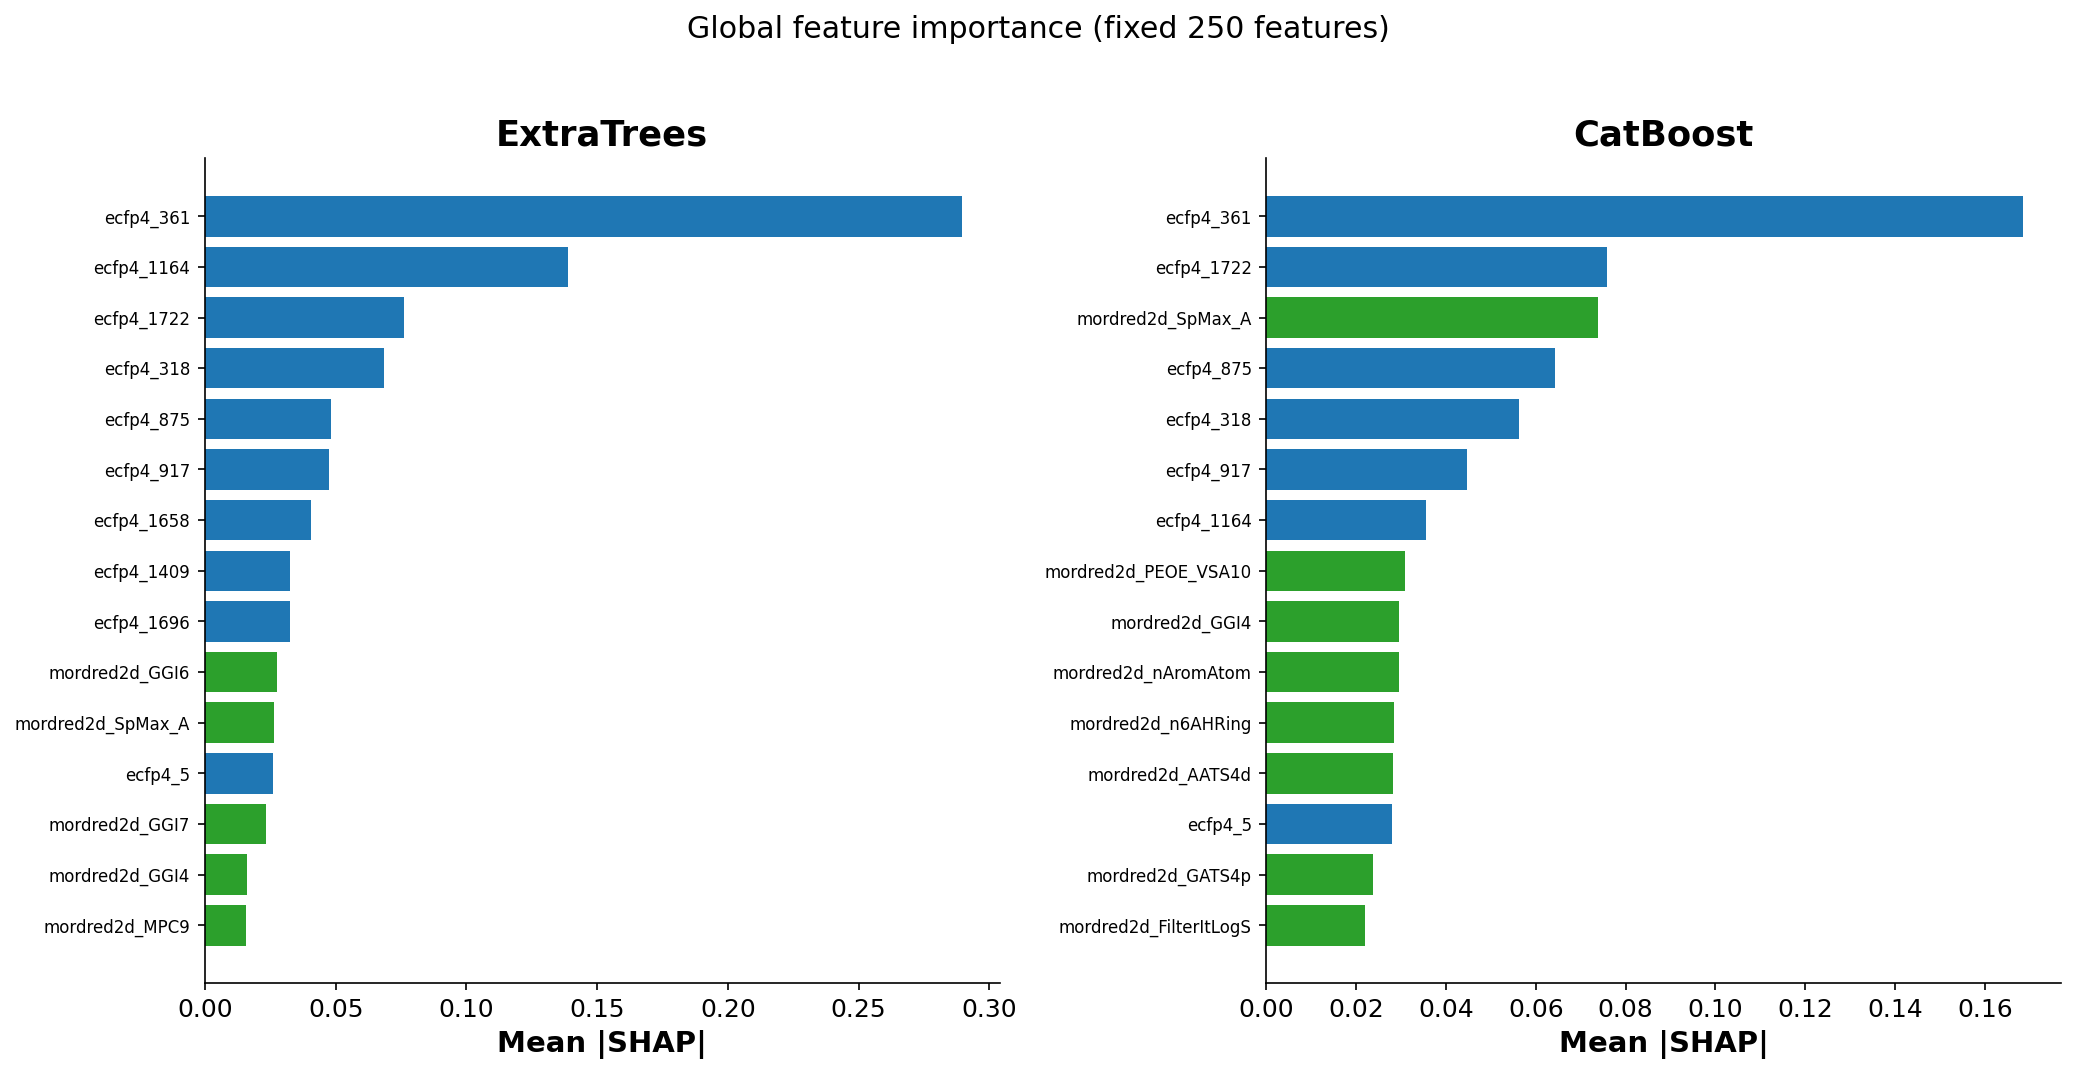

In [4]:
# 4. Global SHAP importance
def global_importance(shap_frame, model_name):
    mean_abs = shap_frame.abs().mean().sort_values(ascending=False)
    mean_signed = shap_frame.mean().reindex(mean_abs.index)
    out = pd.DataFrame({
        "model": model_name,
        "feature": mean_abs.index,
        "mean_abs_shap": mean_abs.values,
        "mean_shap": mean_signed.values,
    })
    out["rank"] = np.arange(1, len(out) + 1)
    out["family"] = out["feature"].map(
        lambda f: "Morgan" if f.startswith("ecfp4_") else (
            "Physicochemical" if f.startswith(("MolWt", "LogP", "TPSA", "HBA", "HBD")) else "Mordred 2D"
        )
    )
    return out

importance_tables = []
for m in MODELS:
    imp = global_importance(shap_by_model[m], m)
    importance_tables.append(imp)
    imp.to_csv(TABLE_DIR / f"global_shap_importance_{MODEL_SHORT[m]}.csv", index=False)

global_imp = pd.concat(importance_tables, ignore_index=True)
global_imp.to_csv(TABLE_DIR / "global_shap_importance_both_models.csv", index=False)

print("Top 12 features by mean |SHAP|:")
display(
    global_imp.groupby("model", sort=False)
    .head(12)[["model", "rank", "feature", "mean_abs_shap", "mean_shap", "family"]]
    .reset_index(drop=True)
    .round(4)
)

# Family contribution
family_summary = (
    global_imp.groupby(["model", "family"], sort=False)
    .agg(mean_abs_shap=("mean_abs_shap", "sum"), n_features=("feature", "count"))
    .reset_index()
)
family_summary.to_csv(TABLE_DIR / "family_shap_contribution.csv", index=False)
display(family_summary.round(4))

# Bar plots of top features
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=False)
for ax, m in zip(axes, MODELS):
    top = global_imp[global_imp.model == m].head(15)
    colours = ["#1f77b4" if f.startswith("ecfp4_") else "#2ca02c" for f in top.feature]
    ax.barh(range(len(top)), top.mean_abs_shap.values[::-1], color=colours[::-1])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.feature.values[::-1], fontsize=8)
    ax.set_xlabel("Mean |SHAP|")
    ax.set_title(MODEL_SHORT[m])
fig.suptitle("Global feature importance (fixed 250 features)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "global_shap_top15_both_models.png", dpi=600, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "global_shap_top15_both_models.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

In [5]:
# 5. Case selection – 10 lowest + 10 median-centered + 10 highest per model
N_PER_GROUP = 10
GROUP_ORDER = ["lowest", "middle", "highest"]

def select_cases(model_name, n_per_group=N_PER_GROUP):
    pred = predictions.loc[predictions.model == model_name].copy()
    pred = pred.sort_values("predicted_pIC50", kind="stable").reset_index(drop=True)
    n = len(pred)
    if n < 3 * n_per_group:
        raise ValueError(f"Not enough test molecules for {model_name}.")

    low_idx = list(range(n_per_group))
    high_idx = list(range(n - n_per_group, n))
    mid_start = max(0, (n // 2) - (n_per_group // 2))
    mid_idx = list(range(mid_start, mid_start + n_per_group))

    rows = []
    for group, indices in zip(GROUP_ORDER, [low_idx, mid_idx, high_idx]):
        for rank, i in enumerate(indices, start=1):
            r = pred.iloc[i]
            rows.append({
                "model": model_name,
                "group": group,
                "rank_within_group": rank,
                "prediction_rank": i + 1,
                "chembl_id": r.chembl_id,
                "predicted_pIC50": float(r.predicted_pIC50),
                "actual_pIC50": float(r.observed_pIC50),
            })
    return pd.DataFrame(rows)

cases_by_model = {m: select_cases(m) for m in MODELS}
all_cases = pd.concat(cases_by_model.values(), ignore_index=True)
all_cases.to_csv(TABLE_DIR / "selected_cases_both_models.csv", index=False)

print("Selected cases summary:")
display(
    all_cases.groupby(["model", "group"], sort=False)
    .agg(
        n=("chembl_id", "count"),
        min_pred=("predicted_pIC50", "min"),
        max_pred=("predicted_pIC50", "max"),
    )
    .round(3)
)
print(f"Total molecules selected: {len(all_cases)}")

Selected cases summary:


n  min_pred  max_pred
model               group                          
ExtraTreesRegressor lowest   10     3.302     3.546
                    middle   10     6.182     6.207
                    highest  10     8.669     9.101
CatBoostRegressor   lowest   10     3.227     3.663
                    middle   10     6.163     6.189
                    highest  10     8.706     9.344

Total molecules selected: 60


In [6]:
# 6. Environment-aware Morgan helpers and drawing utilities
BIT_PALETTE = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728",
    "#9467bd", "#8c564b", "#e377c2", "#17becf",
    "#bcbd22", "#393b79", "#637939", "#843c39",
]
CANVAS_W, CANVAS_H = 1180, 660
MOL_W, MOL_H = 660, 580
TOP_N = 12

def bit_environments(mol):
    """Return bit -> list of (center_atom, radius) occurrences."""
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    MORGAN.GetFingerprint(mol, additionalOutput=ao)
    return dict(ao.GetBitInfoMap())

def environment_atoms_bonds(mol, occurrences):
    atoms, bonds = set(), set()
    for center, radius in occurrences:
        center, radius = int(center), int(radius)
        atoms.add(center)
        env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center)
        for bond_idx in env:
            bond = mol.GetBondWithIdx(int(bond_idx))
            bonds.add(int(bond_idx))
            atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
    return atoms, bonds

def hex_to_rgba(hex_colour, alpha=0.78):
    value = hex_colour.lstrip("#")
    rgb = tuple(int(value[i:i+2], 16) / 255 for i in (0, 2, 4))
    return (*rgb, alpha)

def safe_stem(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(text)).strip("_")

def classify_environment(mol, center, radius):
    """Assign chemical class labels to a single radius-2 environment."""
    labels = set()
    atoms = set([center])
    env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center)
    for bidx in env:
        bond = mol.GetBondWithIdx(int(bidx))
        atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))

    has_aromatic = False
    has_halogen = False
    has_hbd = False
    has_hba = False
    has_polar = False
    only_aliphatic = True

    for aidx in atoms:
        atom = mol.GetAtomWithIdx(int(aidx))
        z = atom.GetAtomicNum()
        if atom.GetIsAromatic():
            has_aromatic = True
            only_aliphatic = False
        if z in (9, 17, 35, 53):  # F, Cl, Br, I
            has_halogen = True
            only_aliphatic = False
        if z in (7, 8) and atom.GetTotalNumHs() > 0:
            has_hbd = True
            has_polar = True
            only_aliphatic = False
        if z in (7, 8):
            has_hba = True
            has_polar = True
            only_aliphatic = False
        if z not in (1, 6):
            only_aliphatic = False
            if z not in (9, 17, 35, 53):
                has_polar = True

    if has_aromatic:
        labels.add("aromatic")
    if only_aliphatic and len(atoms) > 1:
        labels.add("aliphatic")
    if has_hbd:
        labels.add("hbd")
    if has_hba:
        labels.add("hba")
    if has_halogen:
        labels.add("halogen")
    if has_polar and not has_aromatic:
        labels.add("polar")
    if not labels:
        labels.add("other")
    return sorted(labels)

def draw_molecule_with_shap(mol, model_name, case_row, shap_row, feature_values):
    """Draw one molecule with environment-aware Morgan highlighting."""
    chembl_id = case_row.chembl_id
    predicted = case_row.predicted_pIC50
    actual = case_row.actual_pIC50
    group = case_row.group
    rank = case_row.rank_within_group

    # Local SHAP ranking for this molecule
    local = pd.DataFrame({
        "feature": selected_features,
        "shap_value": shap_row[selected_features].values,
        "feature_value": feature_values[selected_features].values,
    })
    local["abs_shap"] = local.shap_value.abs()
    local = local.sort_values("abs_shap", ascending=False, kind="stable")
    top = local.head(TOP_N)

    bit_info = bit_environments(mol)
    mapped_bits = []
    descriptor_entries = []

    for _, row in top.iterrows():
        feat = row.feature
        val = float(row.shap_value)
        raw = float(row.feature_value)
        if feat.startswith("ecfp4_"):
            bit = int(feat.rsplit("_", 1)[1])
            if bit not in bit_info:
                continue
            occ = bit_info[bit]
            atoms, bonds = environment_atoms_bonds(mol, occ)
            env_classes = []
            for center, radius in occ:
                env_classes.extend(classify_environment(mol, center, radius))
            mapped_bits.append({
                "feature": feat,
                "bit": bit,
                "shap": val,
                "raw": raw,
                "atoms": atoms,
                "bonds": bonds,
                "n_occurrences": len(occ),
                "env_classes": sorted(set(env_classes)),
            })
        else:
            descriptor_entries.append((feat, val, raw))

    if len(mapped_bits) > len(BIT_PALETTE):
        mapped_bits = mapped_bits[:len(BIT_PALETTE)]

    # Assign colours and resolve overlaps (strongest |SHAP| wins)
    for i, item in enumerate(mapped_bits):
        item["color_hex"] = BIT_PALETTE[i]

    atom_choice, bond_choice = {}, {}
    for item in mapped_bits:
        colour = hex_to_rgba(item["color_hex"])
        for a in item["atoms"]:
            if a not in atom_choice or abs(item["shap"]) > abs(atom_choice[a][1]):
                atom_choice[a] = (colour, item["shap"], item["bit"])
        for b in item["bonds"]:
            if b not in bond_choice or abs(item["shap"]) > abs(bond_choice[b][1]):
                bond_choice[b] = (colour, item["shap"], item["bit"])

    atom_colours = {i: v[0] for i, v in atom_choice.items()}
    bond_colours = {i: v[0] for i, v in bond_choice.items()}

    # Draw molecule (SVG)
    drawer = rdMolDraw2D.MolDraw2DSVG(MOL_W, MOL_H)
    opts = drawer.drawOptions()
    opts.addAtomIndices = False
    opts.padding = 0.08
    if atom_colours:
        drawer.DrawMolecule(
            mol,
            highlightAtoms=list(atom_colours),
            highlightBonds=list(bond_colours),
            highlightAtomColors=atom_colours,
            highlightBondColors=bond_colours,
        )
    else:
        drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    svg = drawer.GetDrawingText()

    # Build legend text
    legend_lines = [
        f"{MODEL_SHORT[model_name]}  |  {group}  |  rank {rank}",
        f"{chembl_id}",
        f"pred {predicted:.3f}   obs {actual:.3f}",
        "",
        "Morgan bits (colour = bit):",
    ]
    for item in mapped_bits:
        direction = "+" if item["shap"] >= 0 else "−"
        classes = ",".join(item["env_classes"]) if item["env_classes"] else "—"
        legend_lines.append(
            f"  bit {item['bit']:4d}  {direction}{abs(item['shap']):.3f}  "
            f"env={item['n_occurrences']}  [{classes}]"
        )
    if descriptor_entries:
        legend_lines.append("")
        legend_lines.append("Top non-Morgan:")
        for feat, val, raw in descriptor_entries[:6]:
            direction = "+" if val >= 0 else "−"
            legend_lines.append(f"  {feat[:28]:28s}  {direction}{abs(val):.3f}")

    # Composite canvas (molecule + legend) via PIL for PNG
    # We keep the SVG for vector output and also produce a high-dpi PNG.
    stem = f"{MODEL_SHORT[model_name]}_{group}_{rank:02d}_{chembl_id}"
    svg_path = MOL_DIR / f"{stem}.svg"
    png_path = MOL_DIR / f"{stem}.png"

    # Write pure molecule SVG
    with open(svg_path, "w", encoding="utf-8") as fh:
        fh.write(svg)

    # For PNG we rasterise the SVG molecule and add a text legend
    try:
        # Re-draw at higher resolution for PNG
        drawer2 = rdMolDraw2D.MolDraw2DCairo(MOL_W * 2, MOL_H * 2)
        opts2 = drawer2.drawOptions()
        opts2.padding = 0.08
        if atom_colours:
            drawer2.DrawMolecule(
                mol,
                highlightAtoms=list(atom_colours),
                highlightBonds=list(bond_colours),
                highlightAtomColors=atom_colours,
                highlightBondColors=bond_colours,
            )
        else:
            drawer2.DrawMolecule(mol)
        drawer2.FinishDrawing()
        mol_img = Image.open(BytesIO(drawer2.GetDrawingText()))
    except Exception:
        # Fallback: blank panel if Cairo unavailable
        mol_img = Image.new("RGB", (MOL_W * 2, MOL_H * 2), "white")

    # Create canvas and paste
    canvas = Image.new("RGB", (CANVAS_W * 2, CANVAS_H * 2), "white")
    canvas.paste(mol_img, (20, 40))
    draw = ImageDraw.Draw(canvas)
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", 22)
        font_small = ImageFont.truetype("DejaVuSans.ttf", 18)
    except Exception:
        font = ImageFont.load_default()
        font_small = font

    y = 40
    for line in legend_lines:
        draw.text((MOL_W * 2 + 40, y), line, fill="black", font=font_small if line.startswith("  ") else font)
        y += 28 if line.startswith("  ") else 32

    canvas.save(png_path, dpi=(600, 600))

    # Environment mapping rows for the table
    env_rows = []
    for item in mapped_bits:
        env_rows.append({
            "model": model_name,
            "chembl_id": chembl_id,
            "group": group,
            "rank_within_group": rank,
            "feature": item["feature"],
            "bit": item["bit"],
            "shap_value": item["shap"],
            "n_occurrences": item["n_occurrences"],
            "env_classes": ";".join(item["env_classes"]),
            "n_atoms": len(item["atoms"]),
            "n_bonds": len(item["bonds"]),
            "color": item["color_hex"],
        })

    top_feature_rows = []
    for _, row in top.iterrows():
        top_feature_rows.append({
            "model": model_name,
            "chembl_id": chembl_id,
            "group": group,
            "rank_within_group": rank,
            "feature": row.feature,
            "shap_value": float(row.shap_value),
            "abs_shap": float(row.abs_shap),
            "feature_value": float(row.feature_value),
            "is_morgan": row.feature.startswith("ecfp4_"),
        })

    return svg_path, png_path, env_rows, top_feature_rows, mapped_bits


Rendering ExtraTrees molecules ...


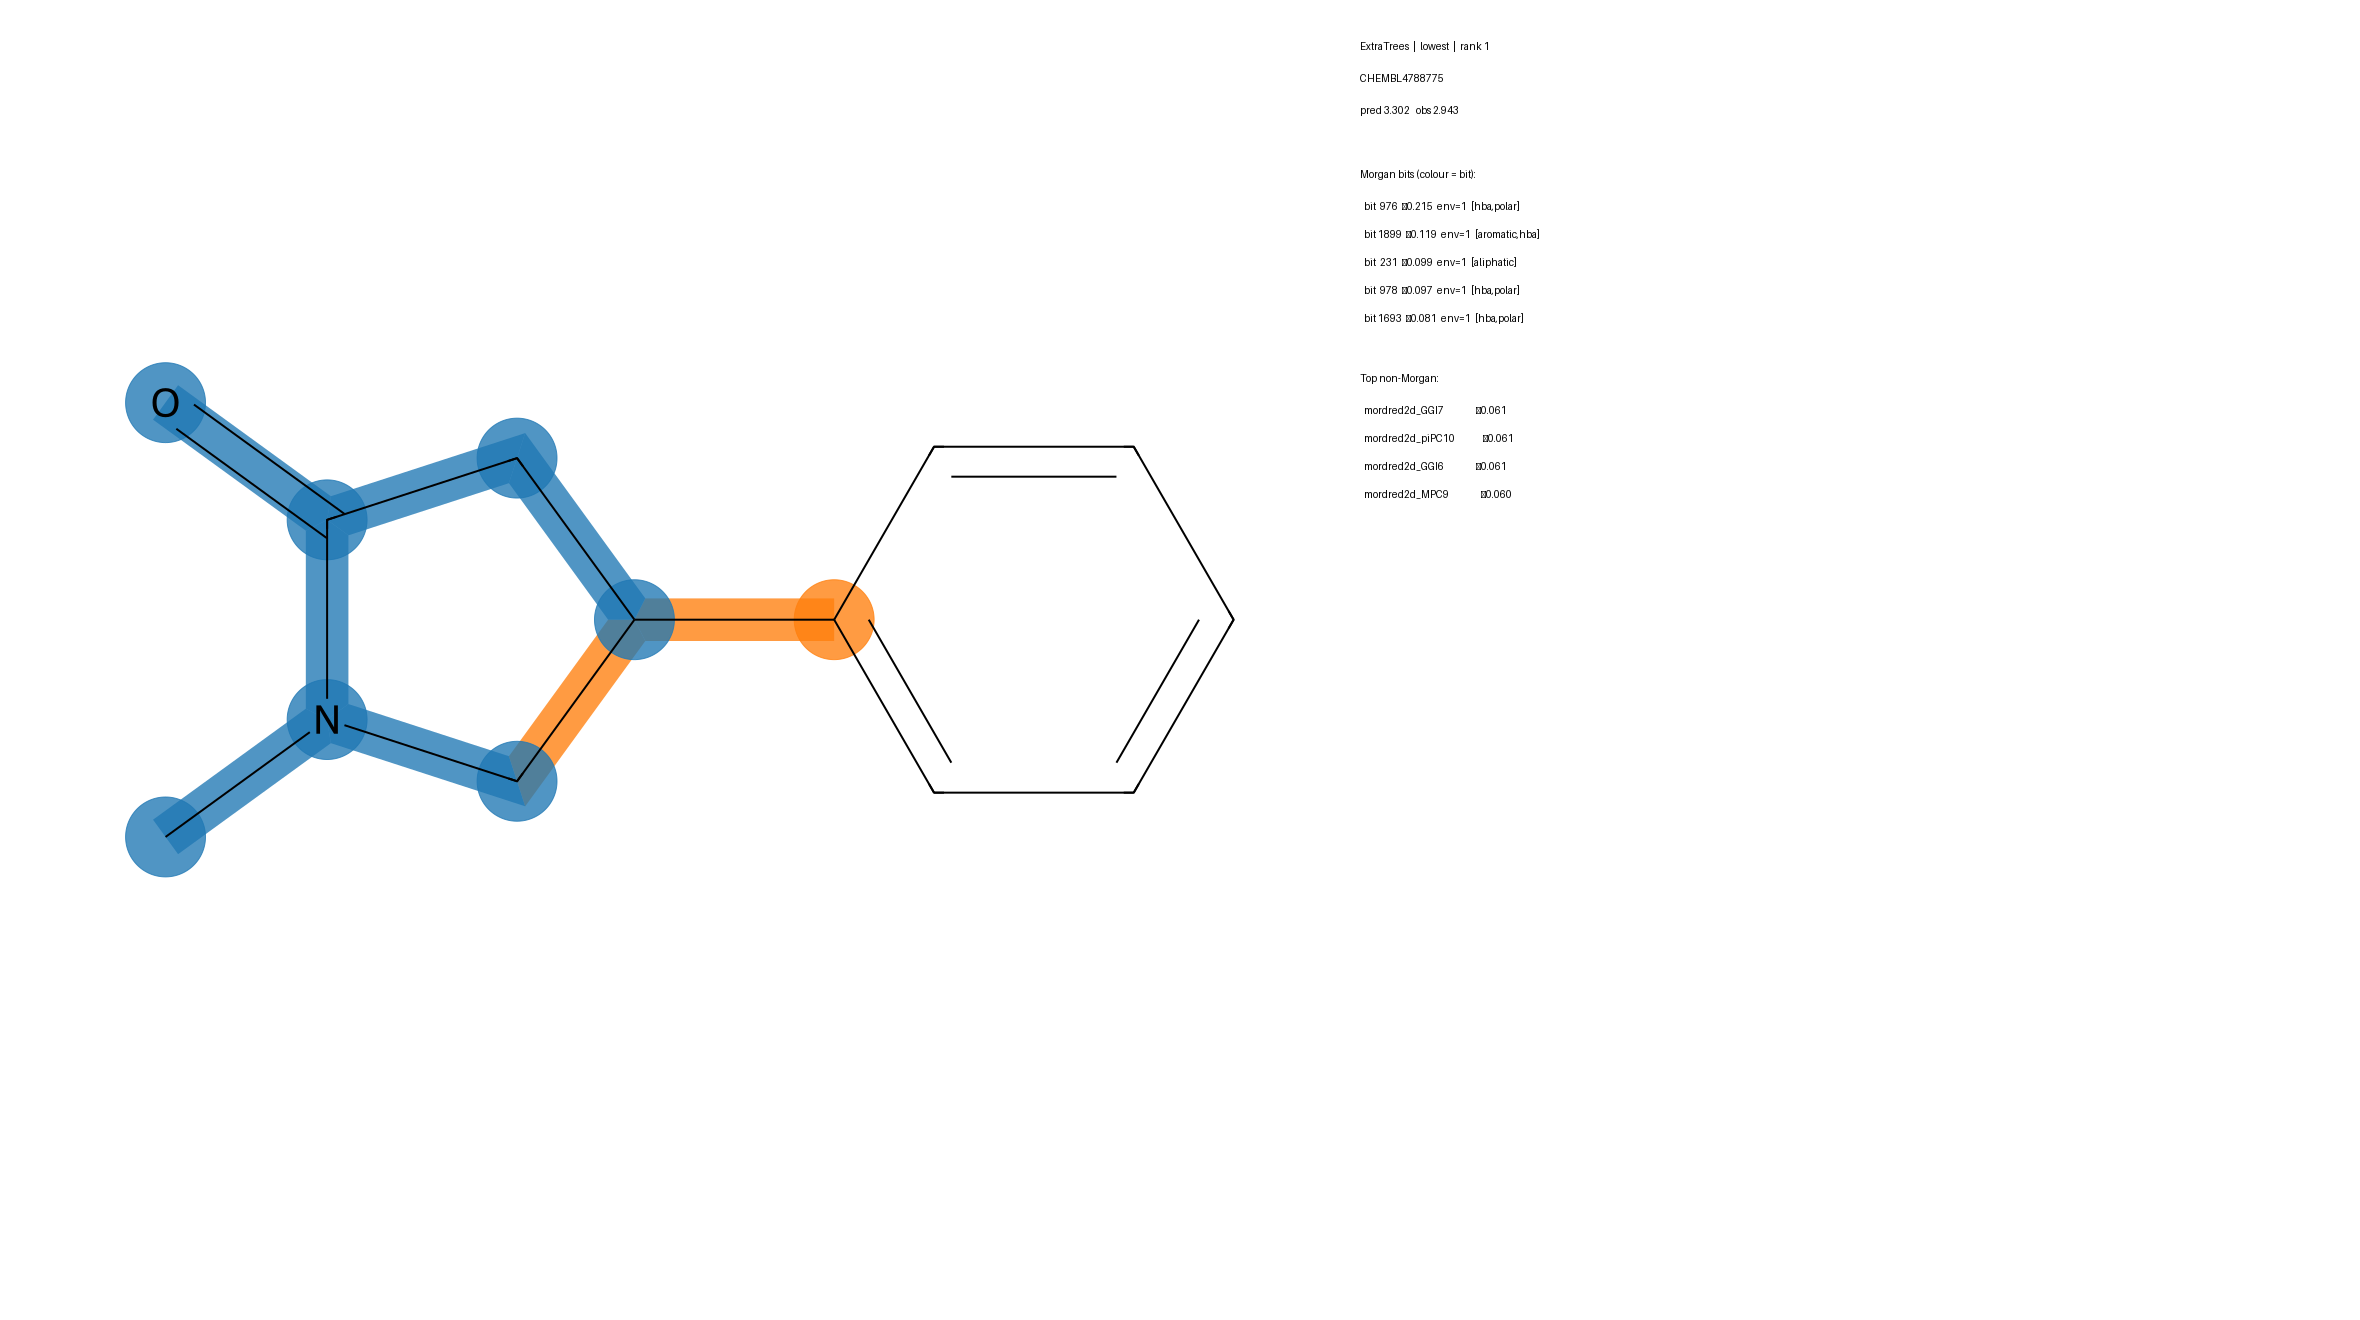

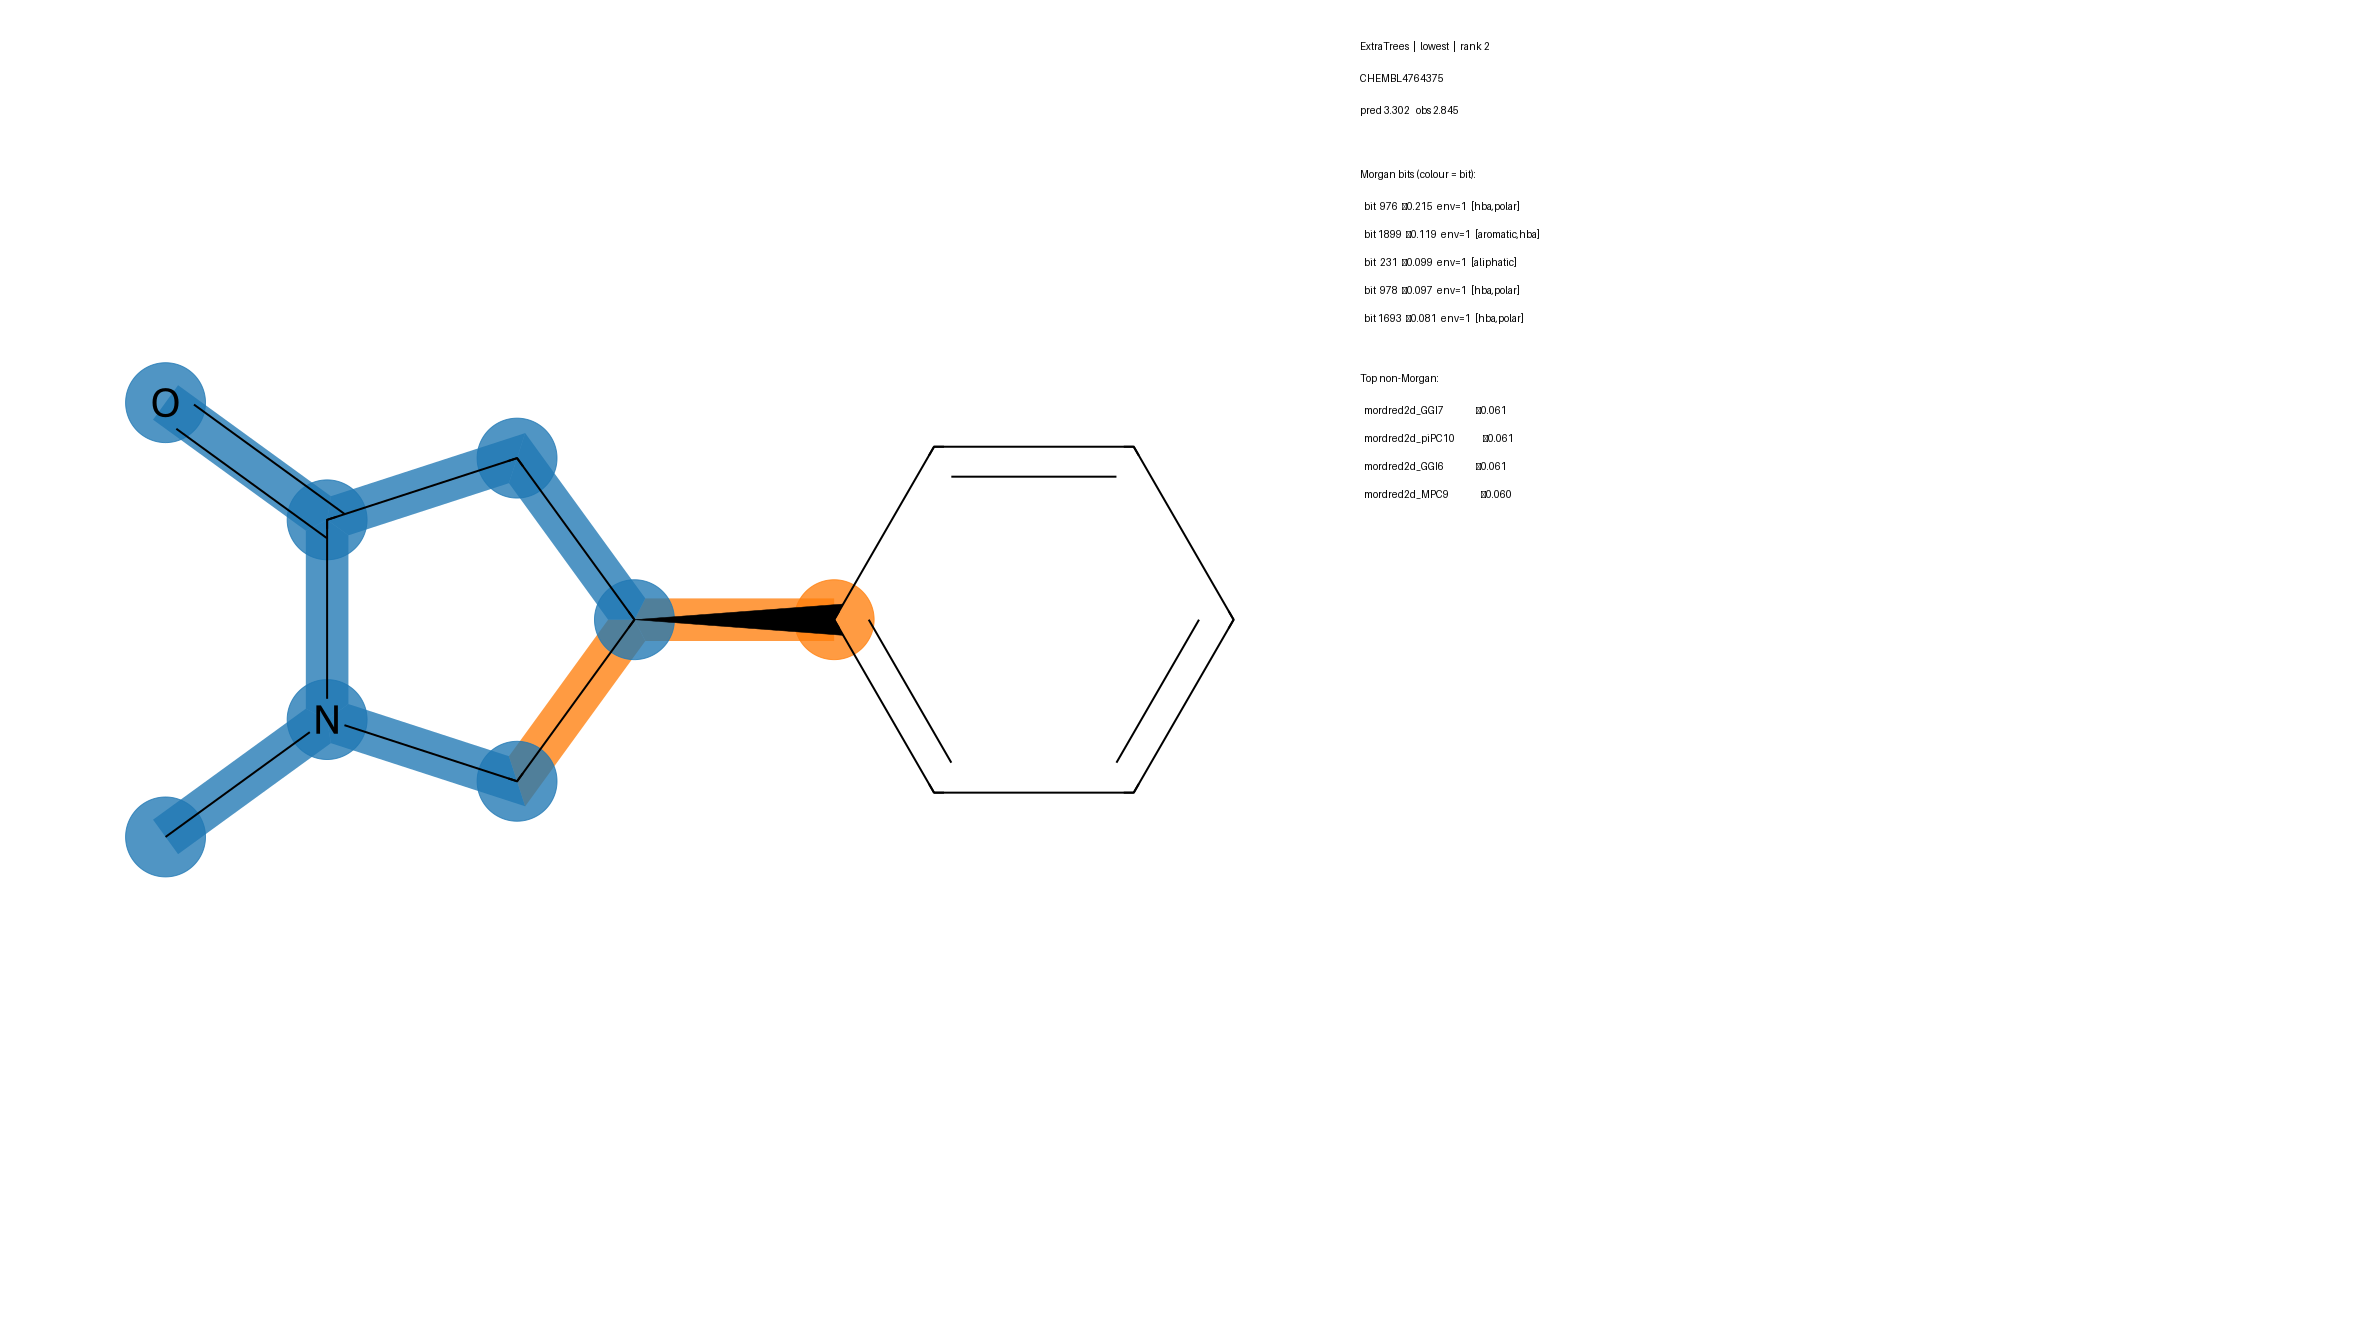

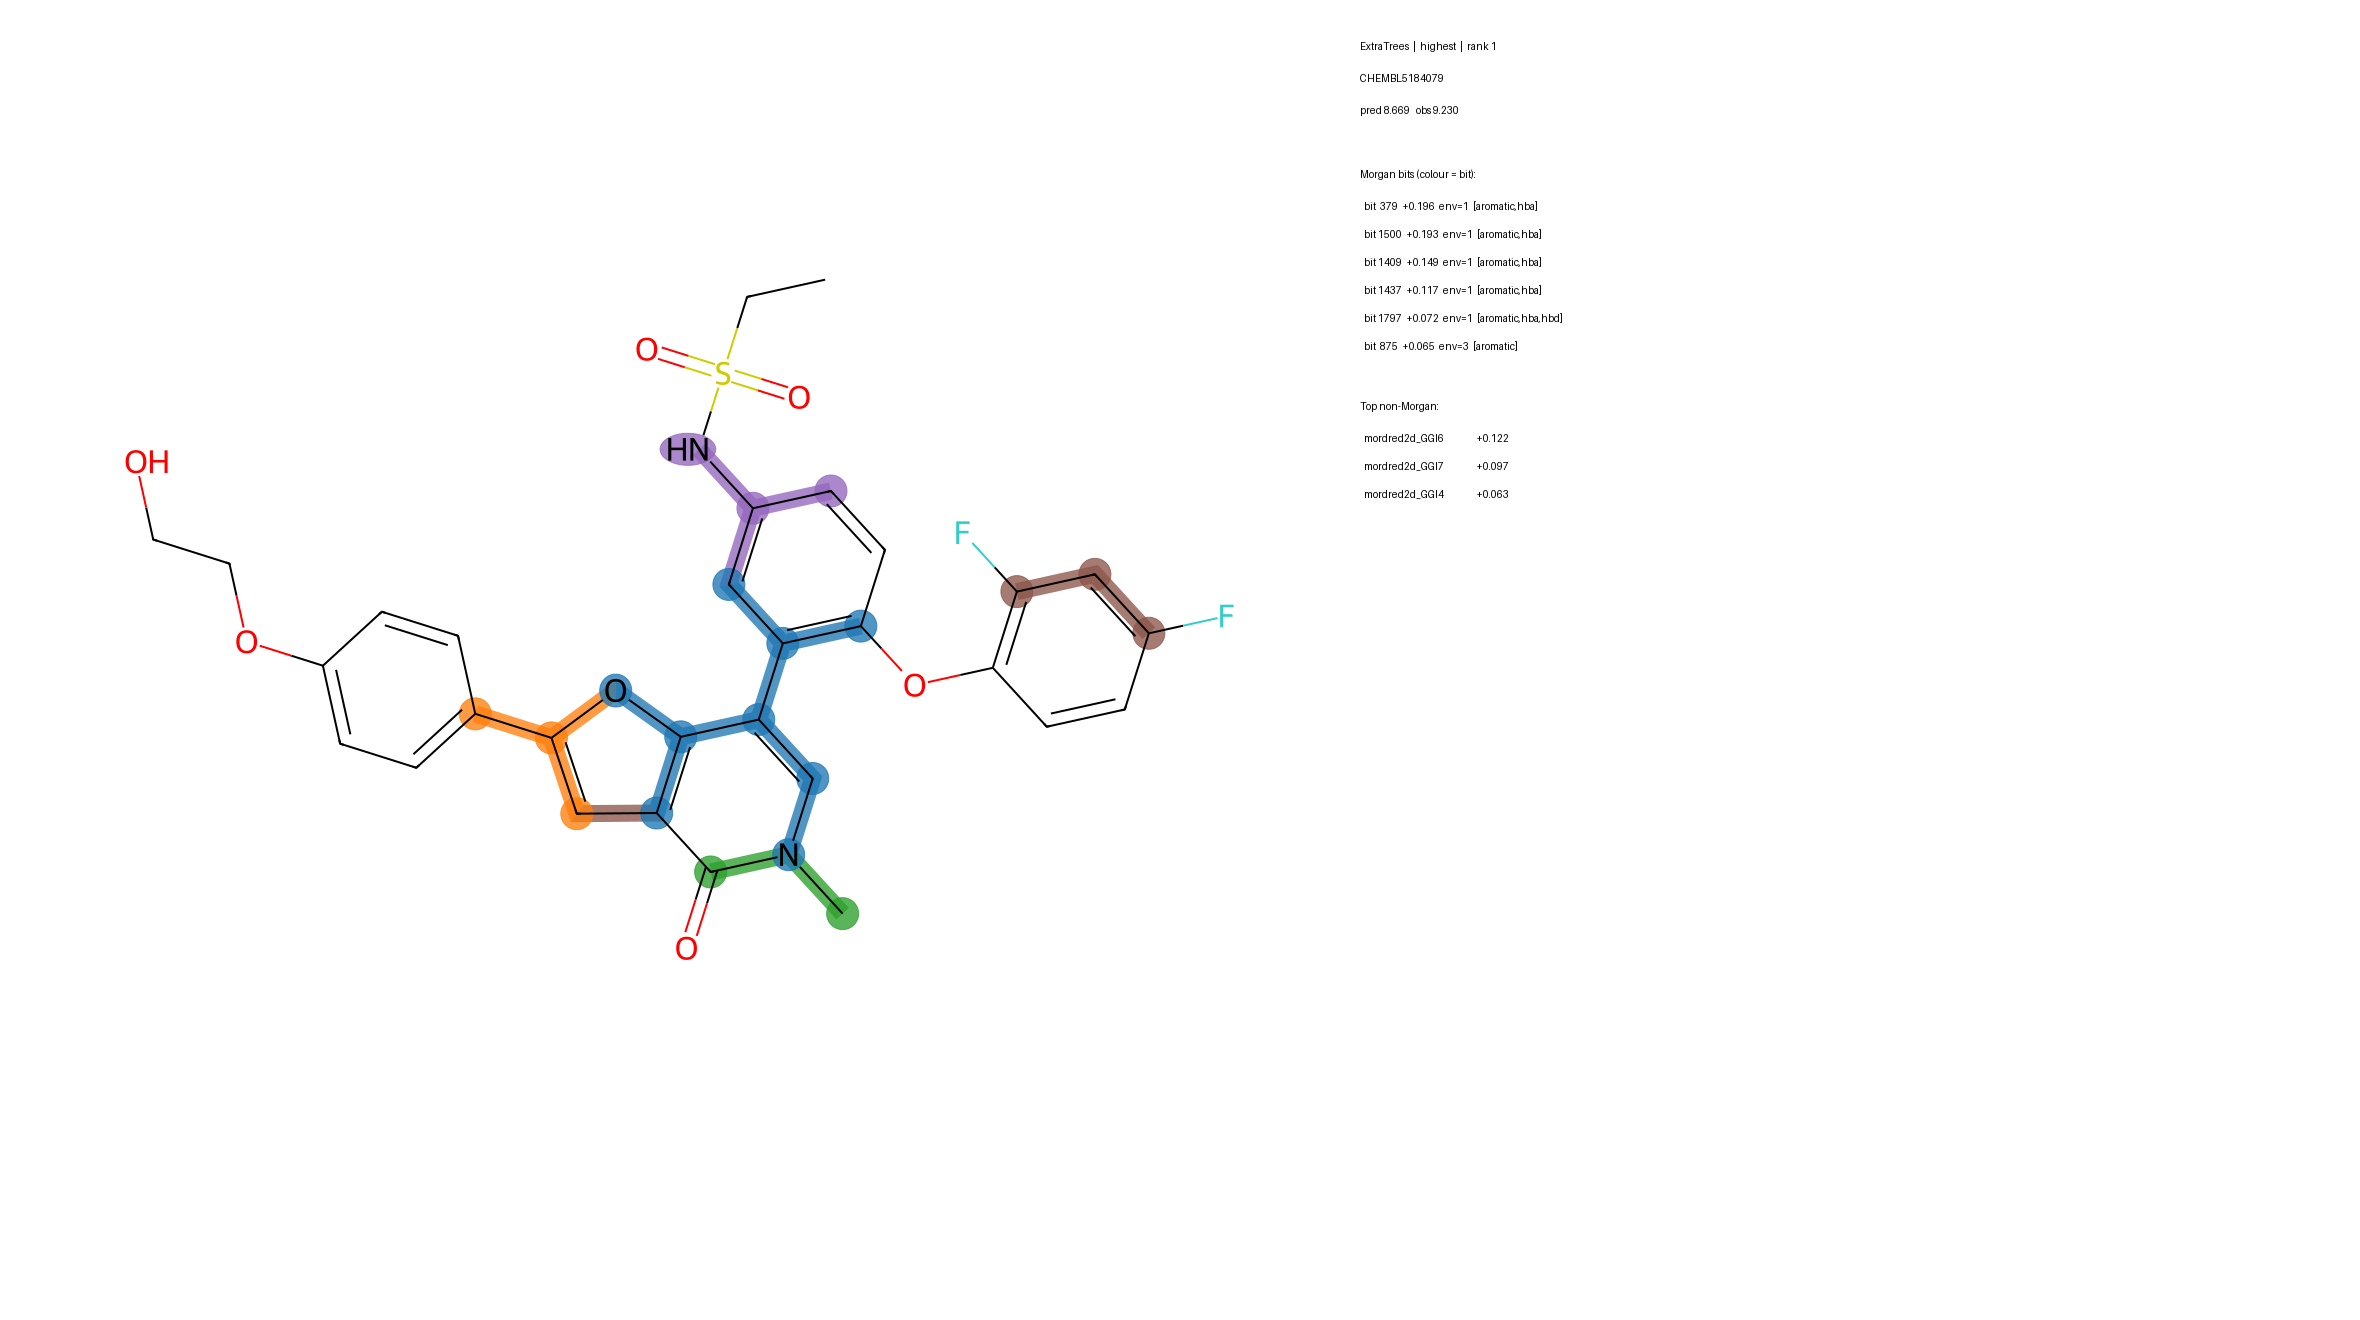

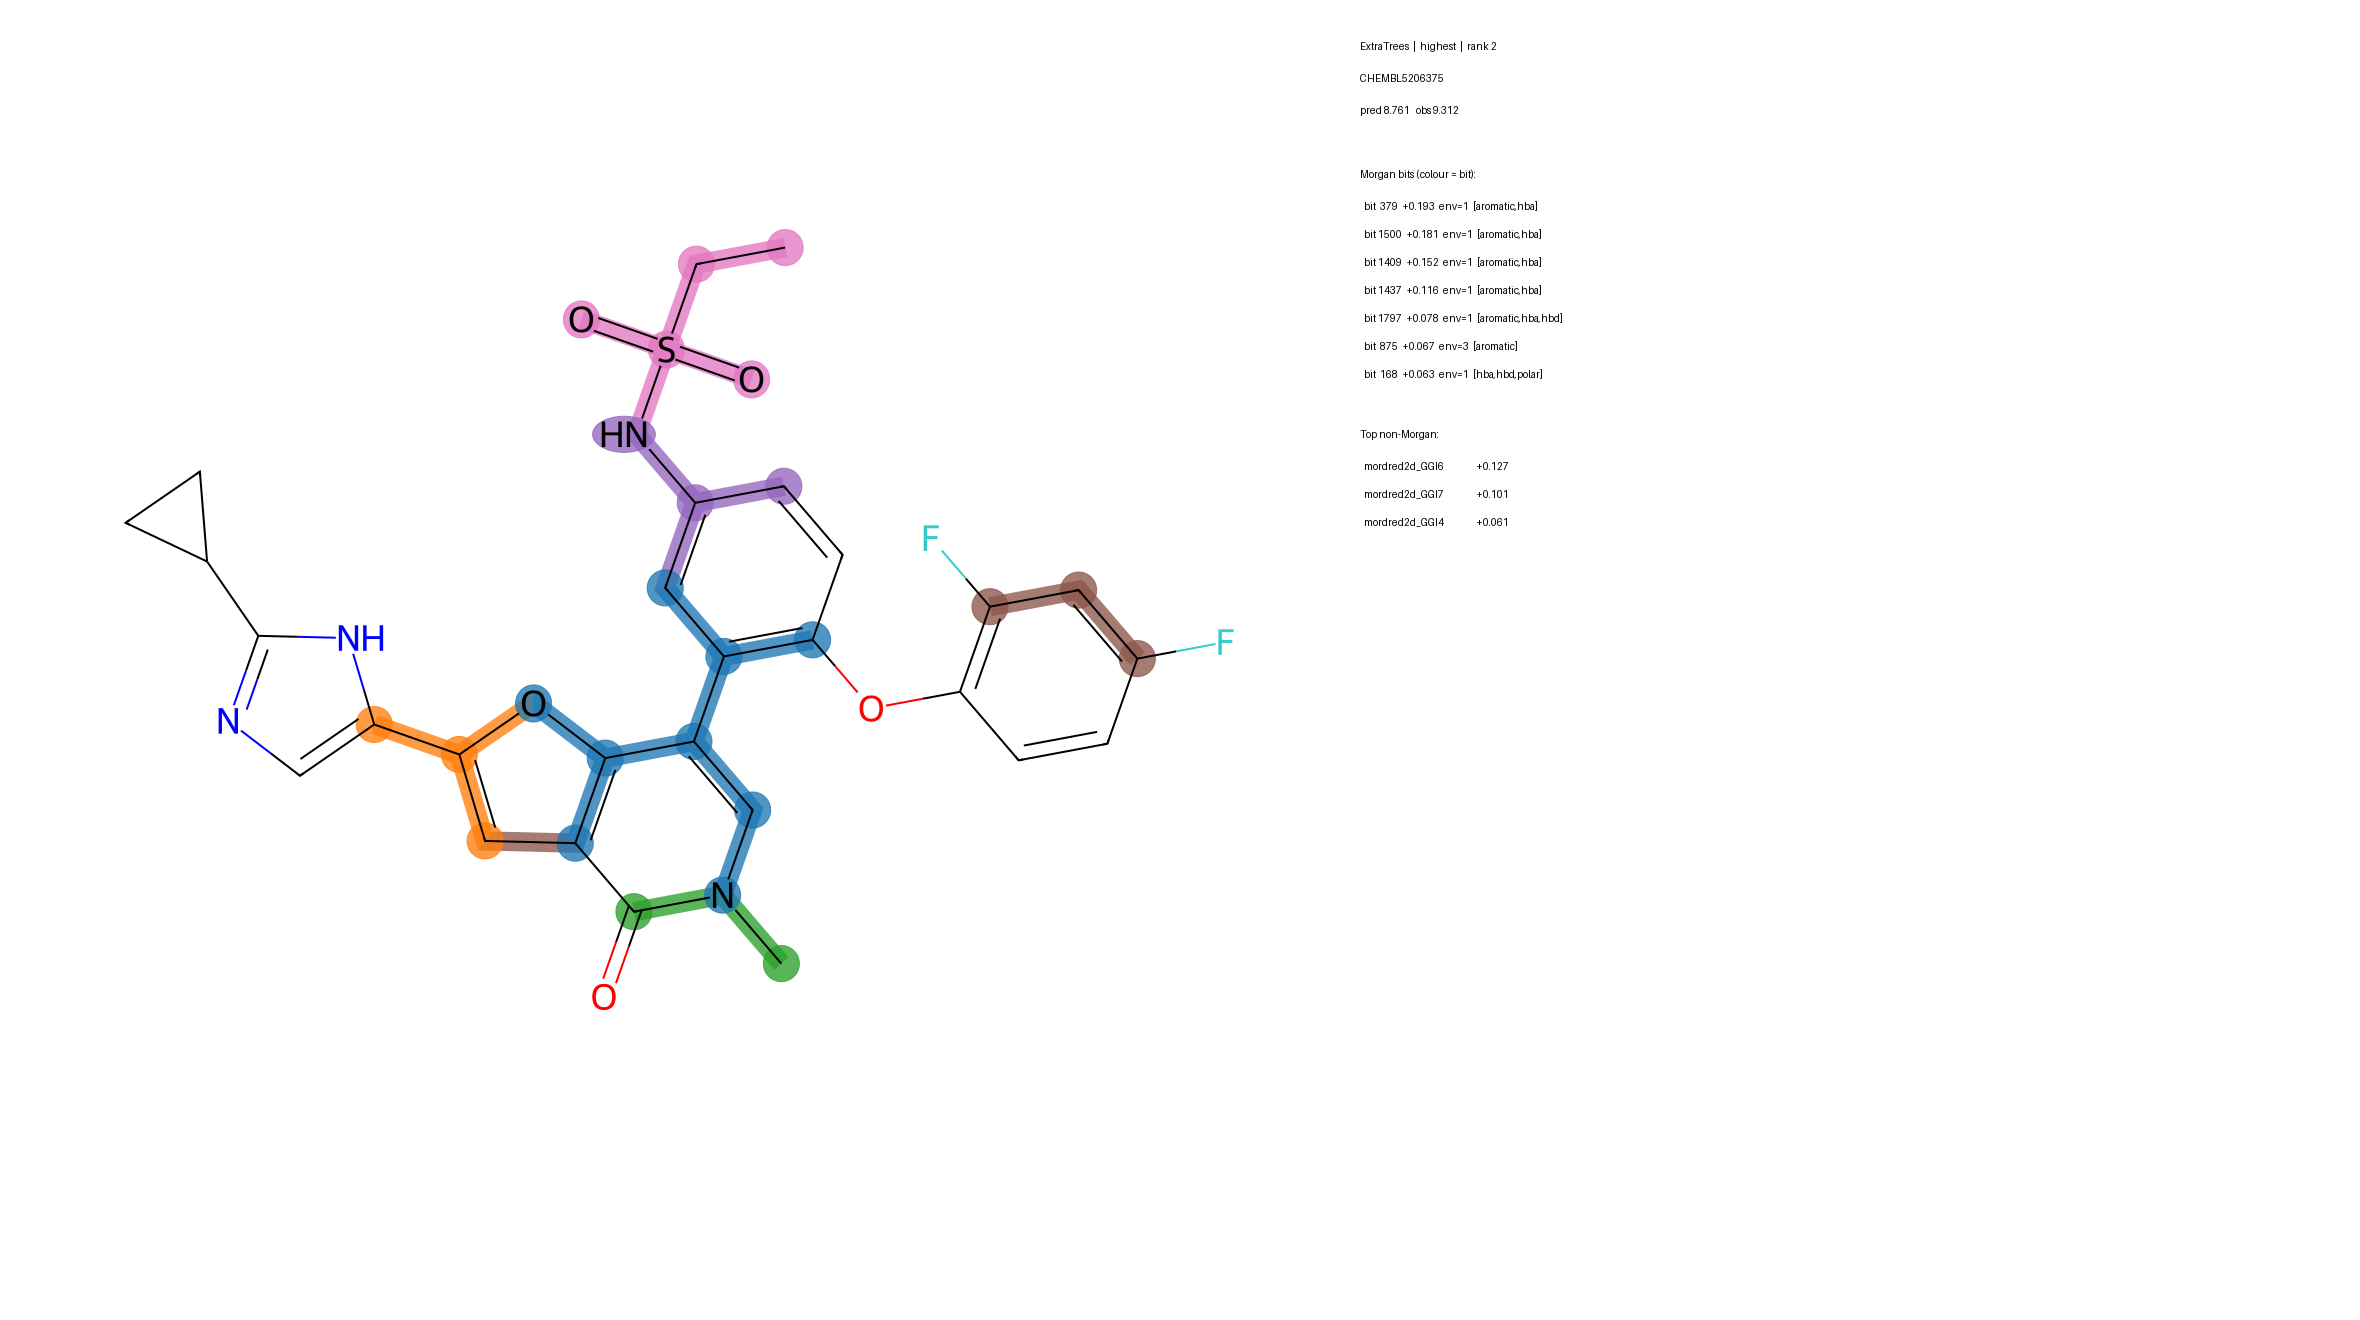


Rendering CatBoost molecules ...


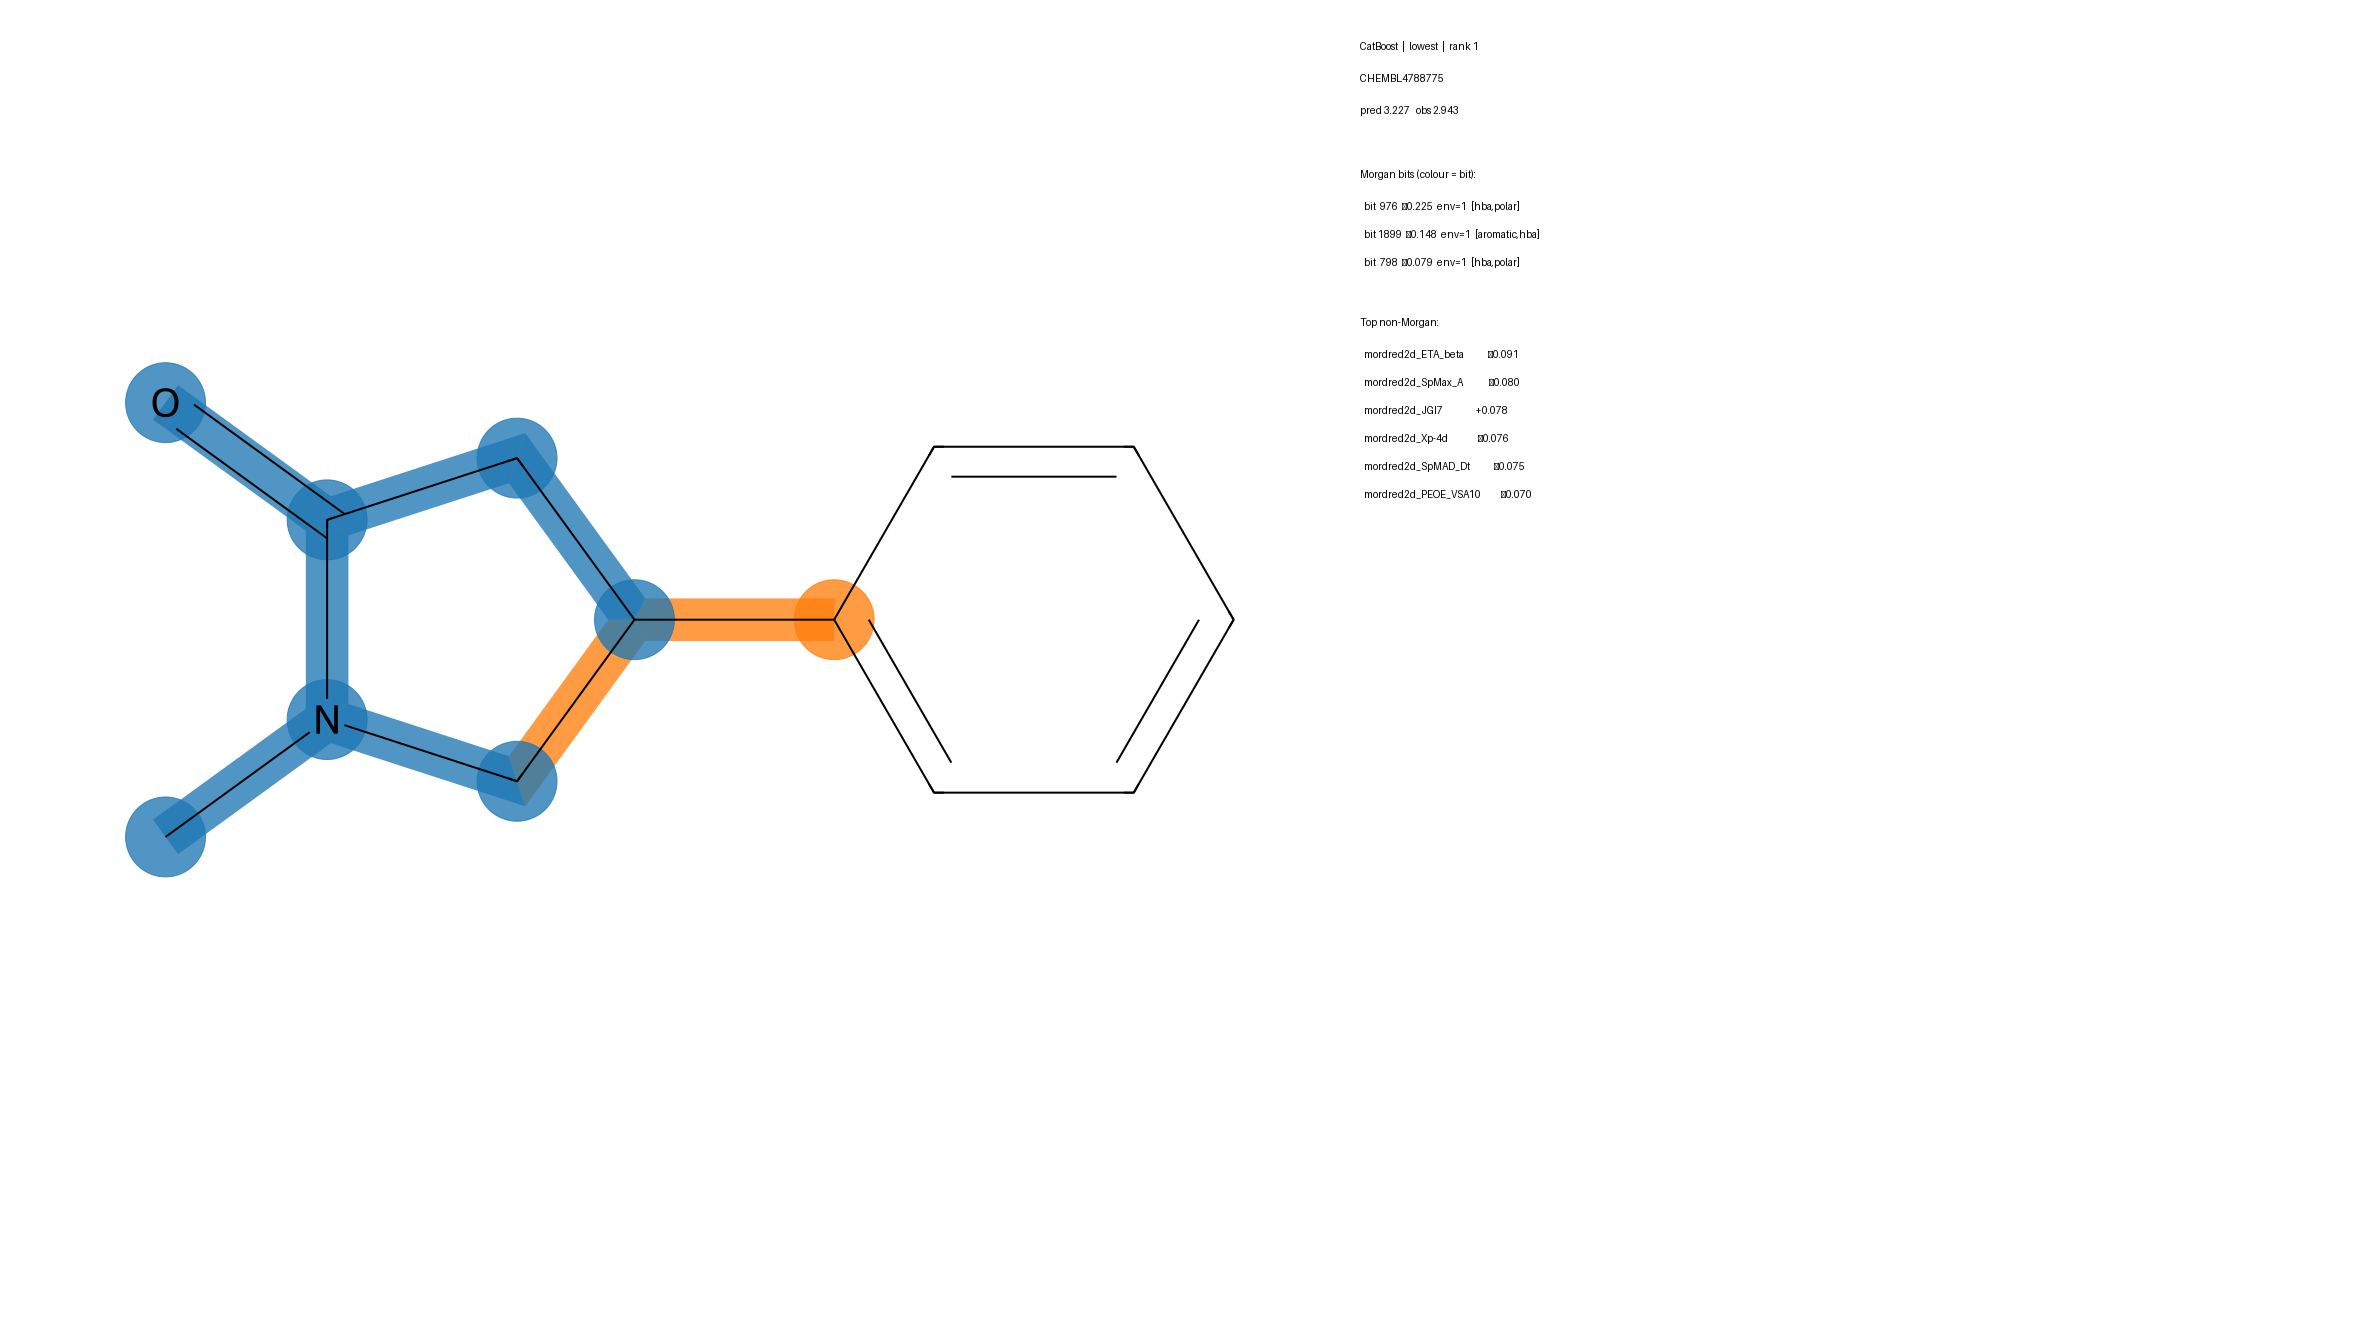

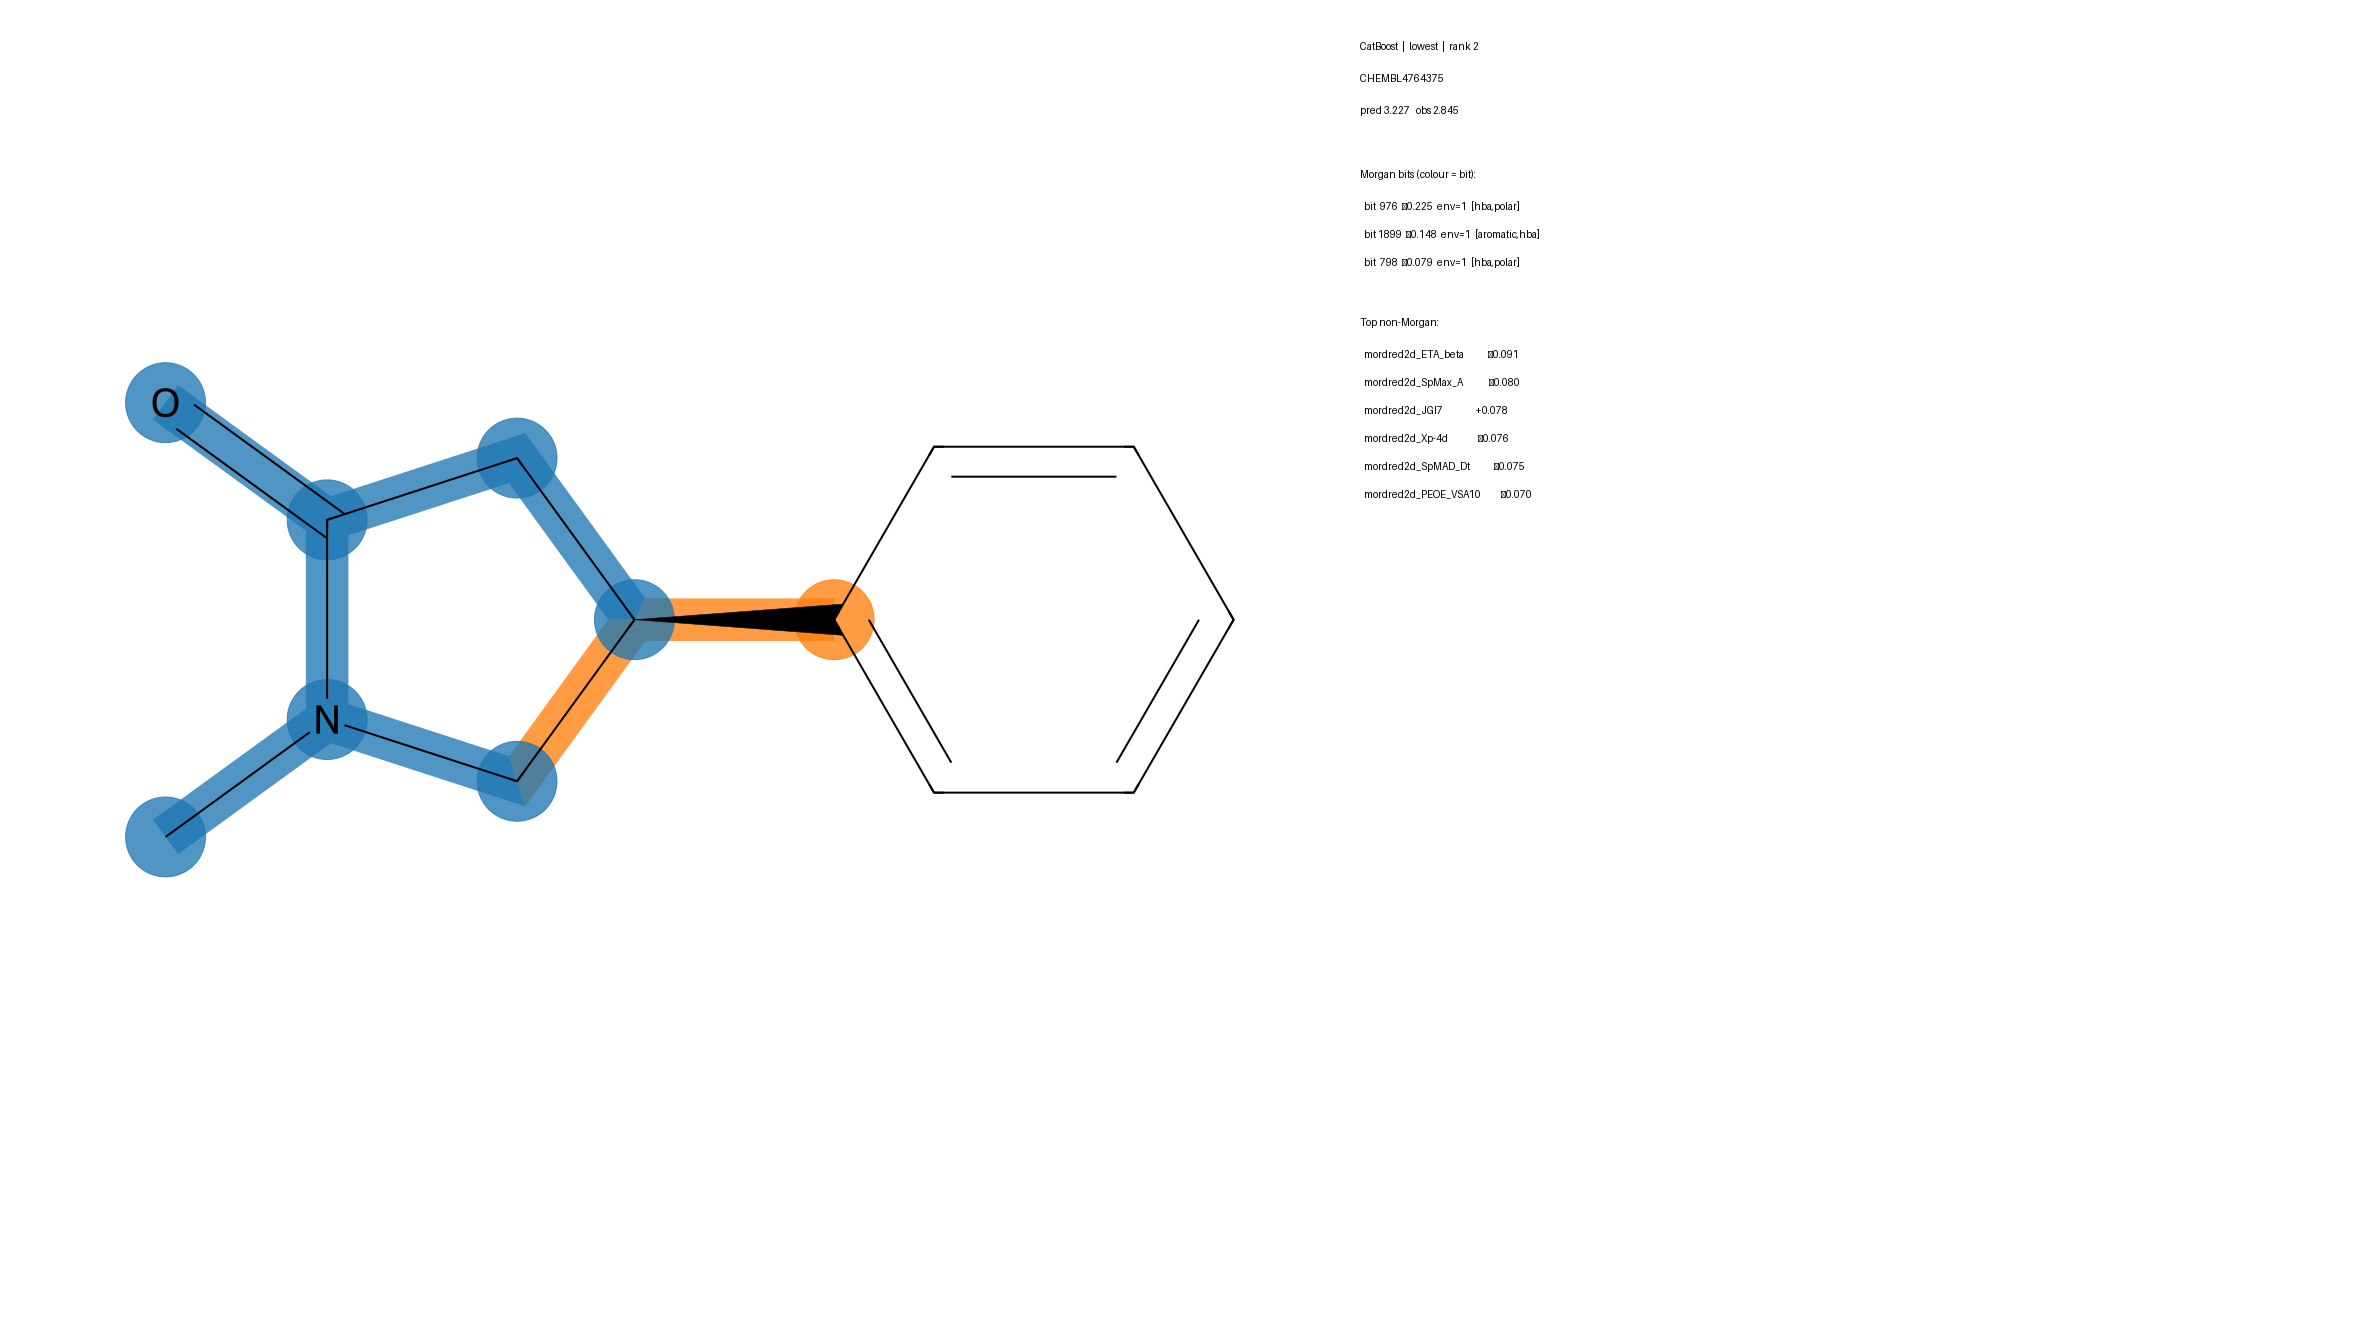

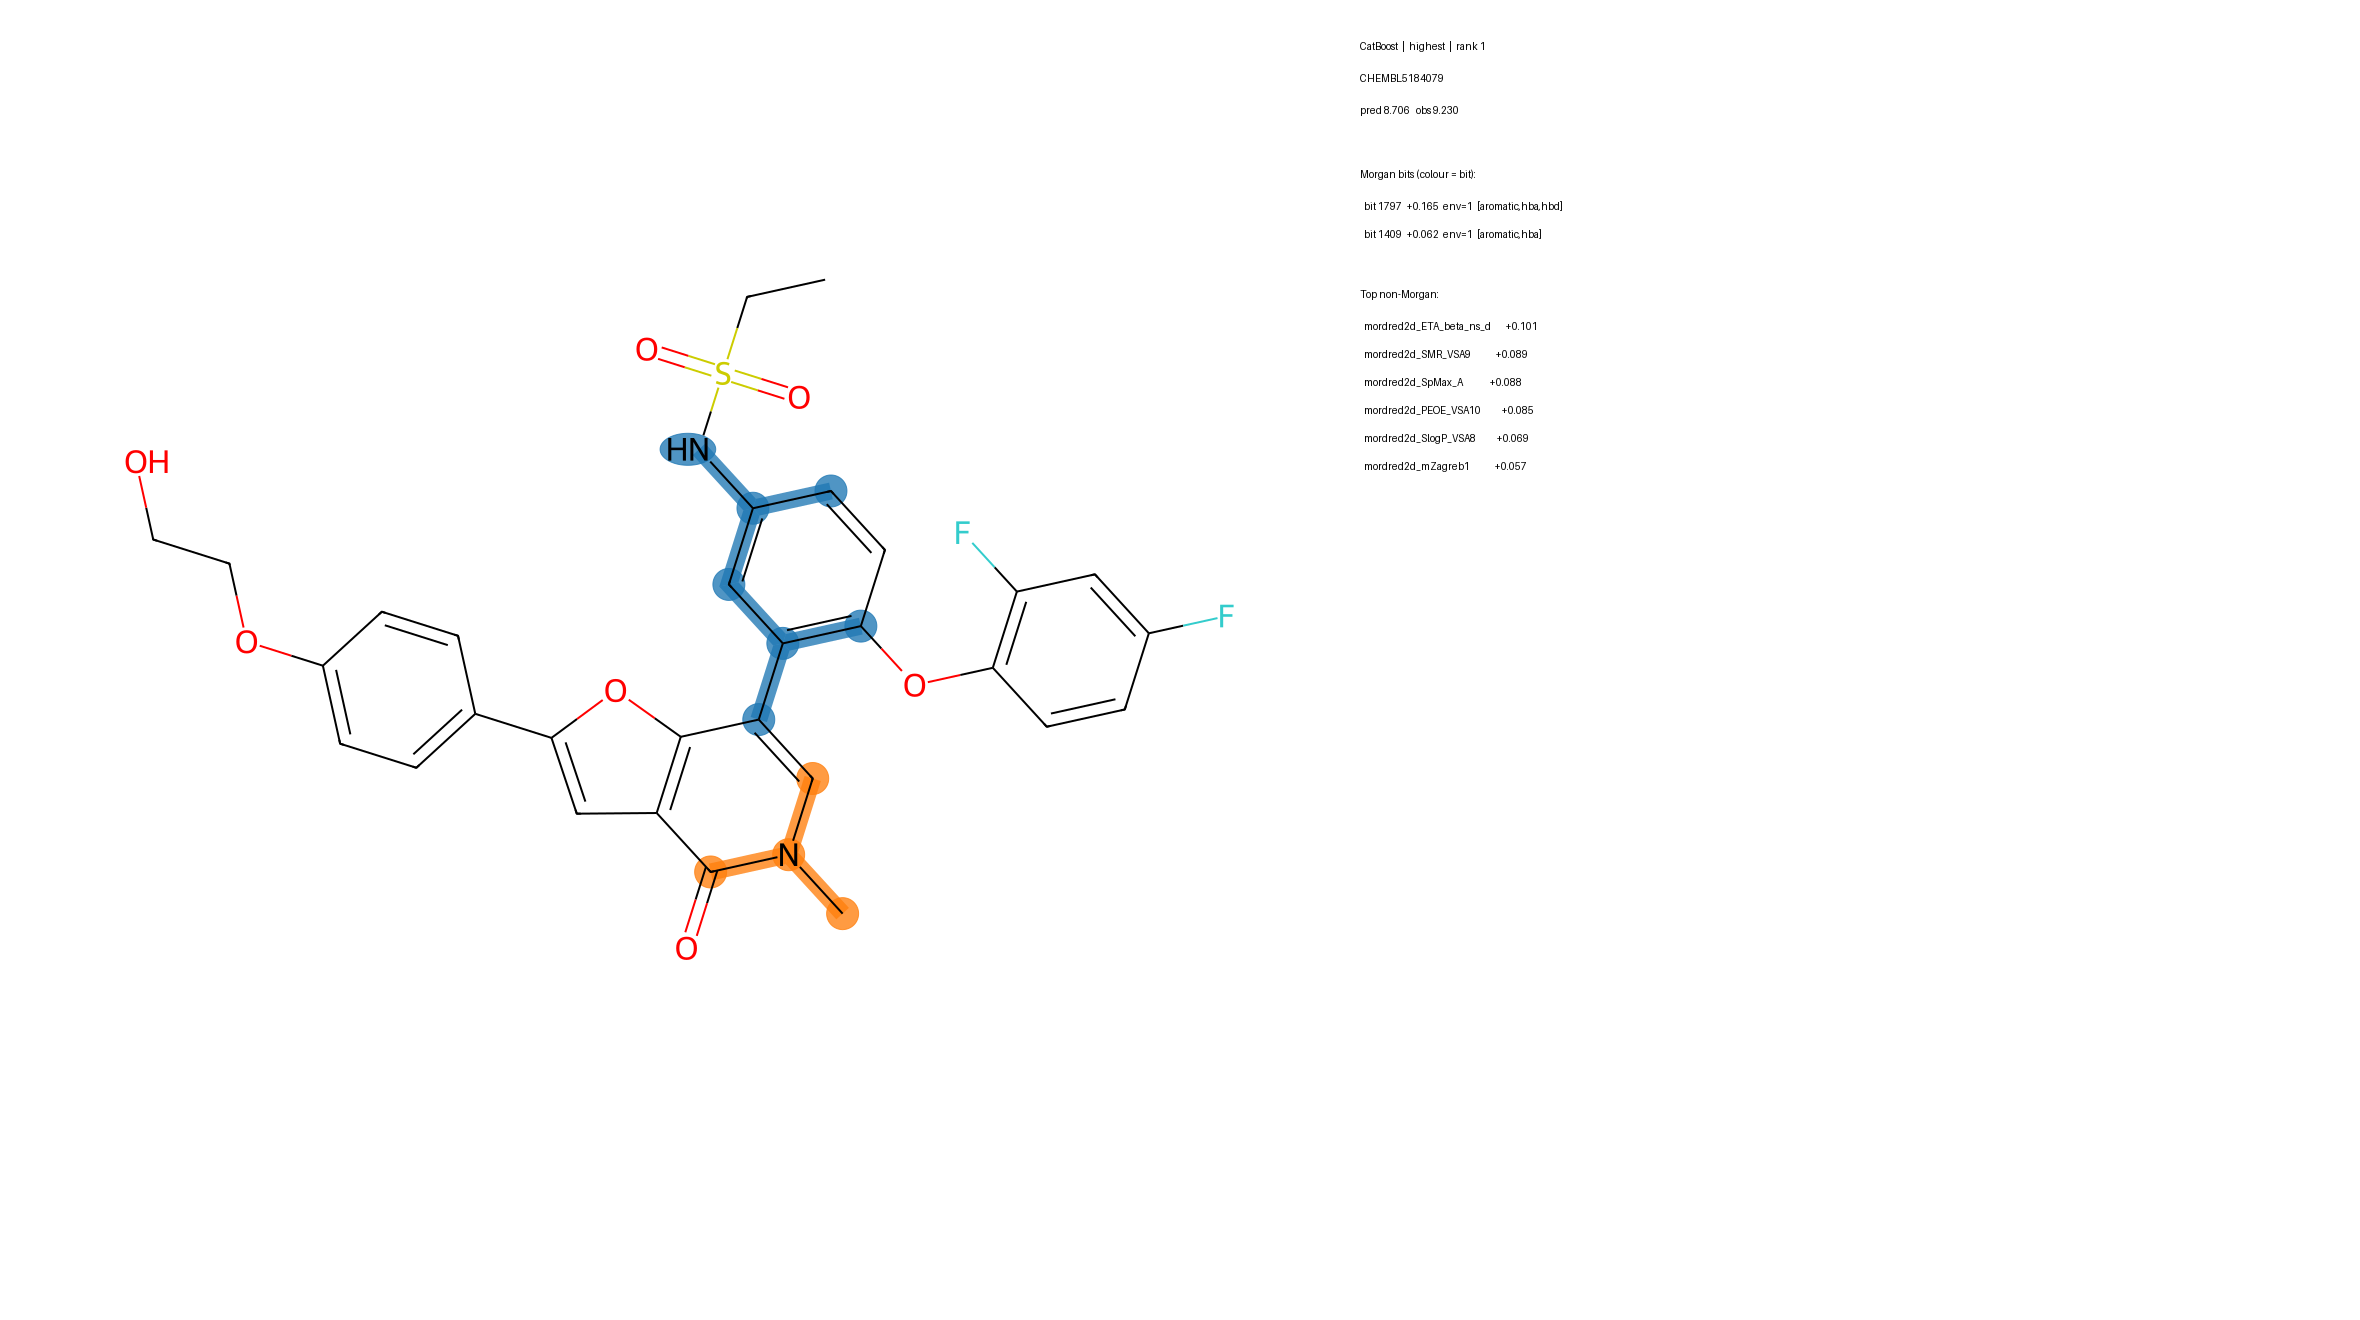

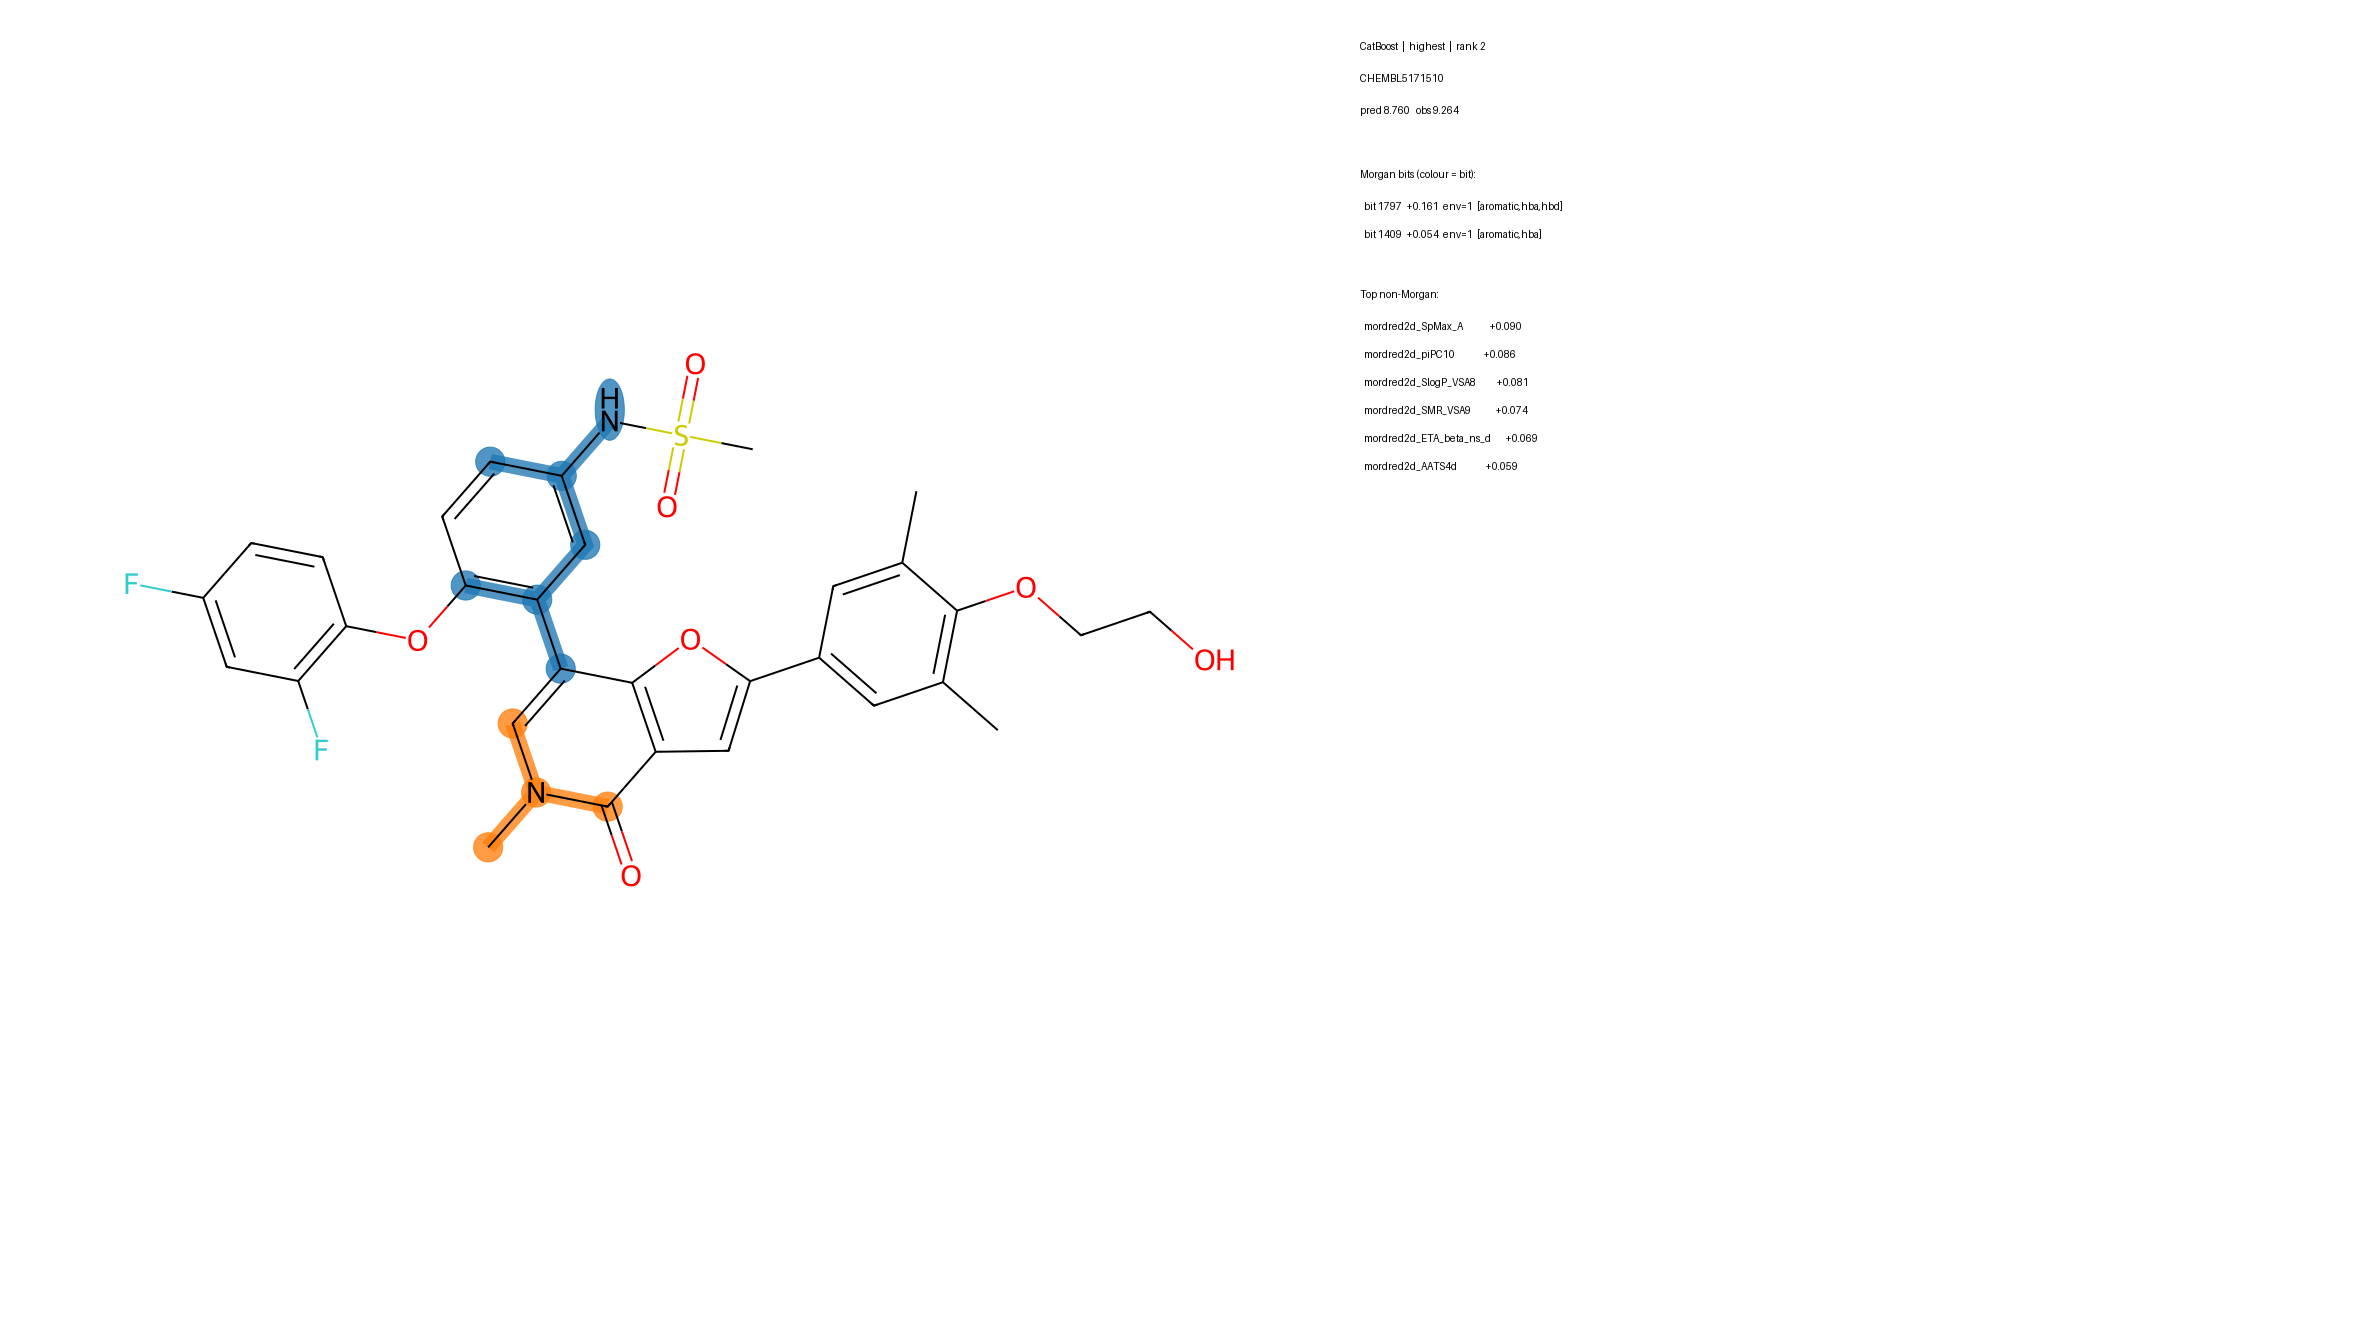


Generated 60 molecular highlight figures.
Environment mapping and local feature tables saved.


In [7]:
# 7. Generate molecular highlights for all selected cases
all_env_rows = []
all_top_feature_rows = []
figure_paths = []

for model_name in MODELS:
    print(f"\nRendering {MODEL_SHORT[model_name]} molecules ...")
    cases = cases_by_model[model_name]
    shap_frame = shap_by_model[model_name]

    for _, case_row in cases.iterrows():
        cid = case_row.chembl_id
        smiles = smiles_by_id[cid]
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            print(f"  WARNING: invalid SMILES for {cid}; skipped.")
            continue

        shap_row = shap_frame.loc[cid]
        feat_vals = X_test.loc[cid]

        svg_path, png_path, env_rows, top_rows, _ = draw_molecule_with_shap(
            mol, model_name, case_row, shap_row, feat_vals
        )
        all_env_rows.extend(env_rows)
        all_top_feature_rows.extend(top_rows)
        figure_paths.append(png_path)

        # Display a small number of examples inline
        if case_row.rank_within_group <= 2 and case_row.group in ("lowest", "highest"):
            display(IPyImage(filename=str(png_path), width=700))

print(f"\nGenerated {len(figure_paths)} molecular highlight figures.")

env_table = pd.DataFrame(all_env_rows)
top_feat_table = pd.DataFrame(all_top_feature_rows)
env_table.to_csv(TABLE_DIR / "morgan_environment_mapping.csv", index=False)
top_feat_table.to_csv(TABLE_DIR / "local_top_features_selected_cases.csv", index=False)
print("Environment mapping and local feature tables saved.")

Pharmacophore-style environment class summary:


,model,env_class,direction,n_occurrences,mean_abs_shap,mean_shap
0,CatBoostRegressor,aromatic,negative,16,0.1234,-0.1234
1,CatBoostRegressor,aromatic,positive,49,0.0710,0.0710
2,CatBoostRegressor,hba,negative,44,0.1303,-0.1303
3,CatBoostRegressor,hba,positive,32,0.0806,0.0806
4,CatBoostRegressor,hbd,positive,10,0.1264,0.1264
5,CatBoostRegressor,polar,negative,28,0.1342,-0.1342
6,CatBoostRegressor,polar,positive,4,0.0777,0.0777
7,ExtraTreesRegressor,aliphatic,negative,10,0.1236,-0.1236
8,ExtraTreesRegressor,aromatic,negative,21,0.1236,-0.1236
9,ExtraTreesRegressor,aromatic,positive,63,0.1520,0.1520



Class frequency (positive vs negative SHAP):


mean_abs_shap          n_occurrences         
direction                          negative positive      negative positive
model               env_class                                              
CatBoostRegressor   aromatic          0.123    0.071          16.0     49.0
                    hba               0.130    0.081          44.0     32.0
                    hbd               0.000    0.126           0.0     10.0
                    polar             0.134    0.078          28.0      4.0
ExtraTreesRegressor aliphatic         0.124    0.000          10.0      0.0
                    aromatic          0.124    0.152          21.0     63.0
                    halogen           0.000    0.027           0.0      1.0
                    hba               0.141    0.172          63.0     50.0
                    hbd               0.020    0.079           1.0     12.0
                    polar             0.144    0.087          44.0      8.0

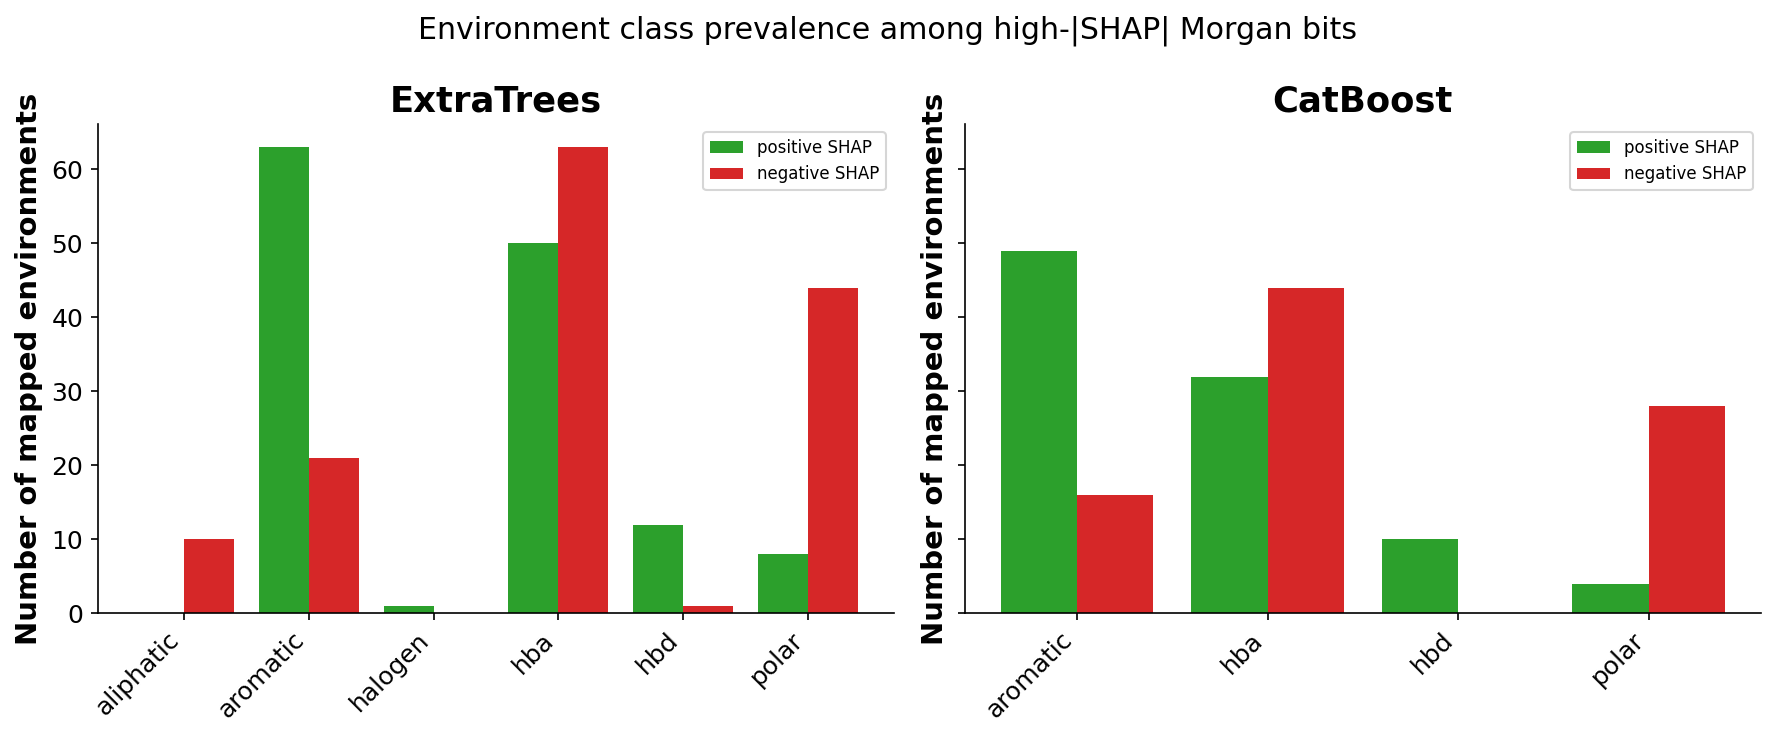

In [8]:
# 8. Bit-to-pharmacophore style grouping
# Aggregate environment classes across all mapped high-SHAP bits
if env_table.empty:
    print("No Morgan environments mapped; skipping pharmacophore grouping.")
else:
    # Expand the semicolon-separated classes
    records = []
    for _, row in env_table.iterrows():
        classes = [c.strip() for c in str(row.env_classes).split(";") if c.strip()]
        direction = "positive" if row.shap_value >= 0 else "negative"
        for cls in classes:
            records.append({
                "model": row.model,
                "chembl_id": row.chembl_id,
                "bit": row.bit,
                "shap_value": row.shap_value,
                "direction": direction,
                "env_class": cls,
            })
    class_df = pd.DataFrame(records)

    # Summary: how often each class appears in positive vs negative contributions
    summary = (
        class_df.groupby(["model", "env_class", "direction"])
        .agg(
            n_occurrences=("bit", "count"),
            mean_abs_shap=("shap_value", lambda s: np.mean(np.abs(s))),
            mean_shap=("shap_value", "mean"),
        )
        .reset_index()
    )
    summary.to_csv(TABLE_DIR / "pharmacophore_style_env_class_summary.csv", index=False)

    print("Pharmacophore-style environment class summary:")
    display(summary.round(4))

    # Pivot for readability
    pivot = summary.pivot_table(
        index=["model", "env_class"],
        columns="direction",
        values=["n_occurrences", "mean_abs_shap"],
        fill_value=0,
    )
    print("\nClass frequency (positive vs negative SHAP):")
    display(pivot.round(3))

    # Simple bar plot of class prevalence
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    for ax, m in zip(axes, MODELS):
        sub = summary[summary.model == m]
        classes = sorted(sub.env_class.unique())
        pos = [sub[(sub.env_class == c) & (sub.direction == "positive")].n_occurrences.sum() for c in classes]
        neg = [sub[(sub.env_class == c) & (sub.direction == "negative")].n_occurrences.sum() for c in classes]
        x = np.arange(len(classes))
        ax.bar(x - 0.2, pos, 0.4, label="positive SHAP", color="#2ca02c")
        ax.bar(x + 0.2, neg, 0.4, label="negative SHAP", color="#d62728")
        ax.set_xticks(x)
        ax.set_xticklabels(classes, rotation=45, ha="right")
        ax.set_title(MODEL_SHORT[m])
        ax.legend(fontsize=8)
        ax.set_ylabel("Number of mapped environments")
    fig.suptitle("Environment class prevalence among high-|SHAP| Morgan bits")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "pharmacophore_env_class_prevalence.png", dpi=600, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "pharmacophore_env_class_prevalence.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 9. Occurrence-specific SMARTS for SHAP-highlighted Morgan environments

This section (formerly Notebook 16) converts the **present ECFP4/Morgan bits that carry the largest local SHAP contributions** into occurrence-specific SMARTS. The cases are no longer typed in by hand: for each model they are chosen from the **current** Stage-08 predictions (highest predicted, median predicted and lowest predicted test molecule), and the bits and SHAP values come from the SHAP matrices recomputed in Section 3.

For every bit occurrence the notebook records the Morgan center atom, radius, atom and bond indices, a fragment SMILES and a SMARTS query. Repeated occurrences of the same bit are separate rows. A hashed bit ID is not a globally unique chemical fragment, so each SMARTS is generated from the actual radius-2 environment in that molecule. Absent bits have no atoms and are not mapped. A bit's SHAP value belongs to the fingerprint feature; when the bit occurs at several locations it is not divided across them or summed over them.

**Scope:** no model is retrained and no feature is reselected. Observed pIC50 values are used for display and descriptive summaries only. Positive and negative SHAP values are model-associated increases or decreases in predicted pIC50, not causal effects.

In [9]:
# 9a. Helpers and representative cases (derived from the CURRENT predictions and SHAP values)
SMARTS_TABLE_DIR = TABLE_DIR / "smarts"
SMARTS_FIG_DIR = FIGURE_DIR / "smarts"
ENV_IMAGE_DIR = SMARTS_FIG_DIR / "morgan_environment_images"
CONTACT_DIR = SMARTS_FIG_DIR / "morgan_environment_contact_sheets"
ALL_TEST_TABLE_DIR = OUT_DIR / "all_test_set_shap" / "tables"
for folder in (SMARTS_TABLE_DIR, ENV_IMAGE_DIR, CONTACT_DIR, ALL_TEST_TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SMARTS_TOP_FEATURES = TOP_N   # same number of top local-|SHAP| features as the molecular highlight figures


def environment_indices(mol, center_atom_idx, radius):
    """Return atom and bond indices for one Morgan atom environment."""
    bond_indices = list(Chem.FindAtomEnvironmentOfRadiusN(mol, int(radius), int(center_atom_idx)))
    atom_indices = {int(center_atom_idx)}
    for bond_idx in bond_indices:
        bond = mol.GetBondWithIdx(int(bond_idx))
        atom_indices.add(int(bond.GetBeginAtomIdx()))
        atom_indices.add(int(bond.GetEndAtomIdx()))
    return sorted(atom_indices), sorted(map(int, bond_indices))


def fragment_strings_with_stereo_fallback(mol, atom_ids, bond_ids):
    """Return SMARTS and Kekule fragment SMILES, retrying if stereo crosses a cut."""
    attempts = [(mol, True, "stereo_preserved")]
    # A cut environment can omit the substituent atoms that define E/Z stereo, so RDKit
    # cannot canonicalize that stereo annotation. Retry on a stereo-free copy; the source
    # molecule and its chirality-aware fingerprint are untouched.
    stereo_free_mol = Chem.Mol(mol)
    Chem.RemoveStereochemistry(stereo_free_mol)
    attempts.append((stereo_free_mol, True, "stereochemistry_removed_at_fragment_boundary"))
    attempts.append((stereo_free_mol, False, "nonisomeric_fallback"))

    errors = []
    for source_mol, isomeric, note in attempts:
        try:
            with rdBase.BlockLogs():
                fragment_smarts = Chem.MolFragmentToSmarts(
                    source_mol, atomsToUse=atom_ids, bondsToUse=bond_ids, isomericSmarts=isomeric)
                fragment_smiles = Chem.MolFragmentToSmiles(
                    source_mol, atomsToUse=atom_ids, bondsToUse=bond_ids,
                    isomericSmiles=isomeric, canonical=True, kekuleSmiles=True)
            if not fragment_smarts or not fragment_smiles:
                raise ValueError("RDKit returned an empty fragment representation.")
            return fragment_smarts, fragment_smiles, note
        except Exception as exc:
            errors.append(f"{type(exc).__name__}: {exc}")
    raise RuntimeError("Could not serialize this Morgan environment: " + " | ".join(errors))


def representative_cases(model_name):
    """Highest, median and lowest PREDICTED test molecule for a model (observed values are not used)."""
    pred = (predictions.loc[predictions.model == model_name]
            .sort_values("predicted_pIC50", kind="stable").reset_index(drop=True))
    n = len(pred)
    picks = [("highest_predicted", n - 1), ("median_predicted", n // 2), ("lowest_predicted", 0)]
    return [(label, pred.iloc[i]) for label, i in picks]


smarts_case_rows, absent_top_rows = [], []
for model_name in MODELS:
    for label, r in representative_cases(model_name):
        cid = r.chembl_id
        local = shap_by_model[model_name].loc[cid]
        top = local.loc[local.abs().sort_values(ascending=False, kind="stable").index[:SMARTS_TOP_FEATURES]]
        bits = {}
        for feat, val in top.items():
            if not feat.startswith("ecfp4_"):
                continue
            bit = int(feat.rsplit("_", 1)[1])
            if float(X_test.at[cid, feat]) >= 0.5:
                bits[bit] = float(val)
            else:   # absent bit: it contributes to the prediction but has no atoms to highlight
                absent_top_rows.append({"model": model_name, "case": label, "chembl_id": cid,
                                        "bit_id": bit, "local_SHAP_contribution_pIC50": float(val),
                                        "reason": "Bit absent from the molecule; no atoms to map."})
        smarts_case_rows.append({
            "model": model_name, "case": label, "chembl_id": cid,
            "predicted_pIC50": float(r.predicted_pIC50), "observed_pIC50": float(r.observed_pIC50),
            "bits": bits,
        })

smarts_cases = pd.DataFrame(smarts_case_rows)
absent_top_bits = pd.DataFrame(absent_top_rows)
print("Representative cases (chosen from current predictions):")
display(smarts_cases.assign(n_present_bits=smarts_cases["bits"].map(len)).drop(columns="bits"))
print("Highlighted present Morgan bits per case:", {f"{r['model'][:5]}|{r['case']}": len(r['bits']) for r in smarts_case_rows})
if len(absent_top_bits):
    print("Top-|SHAP| Morgan bits that are ABSENT from their molecule (not mappable):")
    display(absent_top_bits.round(4))

Representative cases (chosen from current predictions):


,model,case,chembl_id,predicted_pIC50,observed_pIC50,n_present_bits
0,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,9.100509,8.337242,4
1,ExtraTreesRegressor,median_predicted,CHEMBL5819331,6.195535,5.919225,2
2,ExtraTreesRegressor,lowest_predicted,CHEMBL4788775,3.302057,2.943095,5
3,CatBoostRegressor,highest_predicted,CHEMBL6010533,9.343874,8.337242,3
4,CatBoostRegressor,median_predicted,CHEMBL4206831,6.176456,4.468521,2
5,CatBoostRegressor,lowest_predicted,CHEMBL4788775,3.226883,2.943095,3


Highlighted present Morgan bits per case: {'Extra|highest_predicted': 4, 'Extra|median_predicted': 2, 'Extra|lowest_predicted': 5, 'CatBo|highest_predicted': 3, 'CatBo|median_predicted': 2, 'CatBo|lowest_predicted': 3}
Top-|SHAP| Morgan bits that are ABSENT from their molecule (not mappable):


,model,case,chembl_id,bit_id,local_SHAP_contribution_pIC50,reason
0,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,361,0.2607,Bit absent from the molecule; no atoms to map.
1,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,1164,-0.1048,Bit absent from the molecule; no atoms to map.
2,ExtraTreesRegressor,median_predicted,CHEMBL5819331,361,0.1057,Bit absent from the molecule; no atoms to map.
3,ExtraTreesRegressor,median_predicted,CHEMBL5819331,1722,-0.0619,Bit absent from the molecule; no atoms to map.
4,ExtraTreesRegressor,median_predicted,CHEMBL5819331,1164,-0.0504,Bit absent from the molecule; no atoms to map.
5,ExtraTreesRegressor,median_predicted,CHEMBL5819331,318,0.0287,Bit absent from the molecule; no atoms to map.
6,ExtraTreesRegressor,median_predicted,CHEMBL5819331,5,-0.0282,Bit absent from the molecule; no atoms to map.
7,ExtraTreesRegressor,median_predicted,CHEMBL5819331,1696,-0.0227,Bit absent from the molecule; no atoms to map.
8,ExtraTreesRegressor,median_predicted,CHEMBL5819331,917,-0.0205,Bit absent from the molecule; no atoms to map.
9,ExtraTreesRegressor,lowest_predicted,CHEMBL4788775,1722,-0.1540,Bit absent from the molecule; no atoms to map.


In [10]:
# 9b. Extract each highlighted bit occurrence and generate SMARTS
smarts_molecules = {}
for cid in smarts_cases.chembl_id.unique():
    mol = Chem.MolFromSmiles(smiles_by_id[cid])
    if mol is None:
        raise ValueError(f"RDKit could not parse standardized SMILES for {cid}.")
    smarts_molecules[cid] = mol

environment_rows, missing_bit_rows = [], []
for case in smarts_case_rows:
    chembl_id = case["chembl_id"]
    mol = smarts_molecules[chembl_id]

    additional = rdFingerprintGenerator.AdditionalOutput()
    additional.AllocateBitInfoMap()
    fingerprint = MORGAN.GetFingerprint(mol, additionalOutput=additional)
    on_bits = set(map(int, fingerprint.GetOnBits()))
    bit_info = additional.GetBitInfoMap()

    for bit_id, local_shap in case["bits"].items():
        bit_id = int(bit_id)
        occurrences = bit_info.get(bit_id, ())
        if bit_id not in on_bits or not occurrences:
            missing_bit_rows.append({
                "model": case["model"], "case": case["case"], "chembl_id": chembl_id, "bit_id": bit_id,
                "reason": "Feature matrix says present, but the bit is absent from the regenerated Morgan "
                          "fingerprint; check standardization/fingerprint settings."})
            continue

        for occurrence_no, (center_atom_idx, radius) in enumerate(occurrences, start=1):
            atom_indices, bond_indices = environment_indices(mol, center_atom_idx, radius)
            smarts, fragment_smiles, stereo_note = fragment_strings_with_stereo_fallback(mol, atom_indices, bond_indices)
            with rdBase.BlockLogs():
                query = Chem.MolFromSmarts(smarts)
            query_parses = query is not None
            n_matches = len(mol.GetSubstructMatches(query, uniquify=True)) if query_parses else 0

            environment_rows.append({
                "model": case["model"], "case": case["case"], "chembl_id": chembl_id,
                "predicted_pIC50": case["predicted_pIC50"], "observed_pIC50": case["observed_pIC50"],
                "bit_feature": f"ecfp4_{bit_id}", "bit_id": bit_id,
                "local_SHAP_contribution_pIC50": float(local_shap),
                "occurrence_in_molecule": occurrence_no, "n_occurrences_of_bit": len(occurrences),
                "center_atom_index_0based": int(center_atom_idx), "radius": int(radius),
                "atom_indices_0based": ",".join(map(str, atom_indices)),
                "bond_indices_0based": ",".join(map(str, bond_indices)),
                "fragment_SMILES": fragment_smiles, "SMARTS": smarts,
                "SMARTS_stereo_fallback": stereo_note != "stereo_preserved",
                "SMARTS_generation_note": stereo_note,
                "SMARTS_parses": bool(query_parses),
                "SMARTS_matches_in_source_molecule": int(n_matches),
                "source_canonical_SMILES": smiles_by_id[chembl_id],
            })

environments = pd.DataFrame(environment_rows)
missing_bits = pd.DataFrame(missing_bit_rows)

if environments.empty:
    raise RuntimeError("No highlighted Morgan environments were recovered. Check fingerprint settings and structures.")
if not environments["SMARTS_parses"].all():
    raise ValueError("At least one generated SMARTS did not parse. Inspect the environment table.")

print("SMARTS rows (one row per bit occurrence):", len(environments))
print("Unique model/case/bit combinations:", environments[["model", "case", "bit_id"]].drop_duplicates().shape[0])
print("Missing/mismatched highlighted bits:", len(missing_bits))
display(environments[["model", "case", "chembl_id", "bit_feature", "occurrence_in_molecule",
                      "center_atom_index_0based", "radius", "local_SHAP_contribution_pIC50",
                      "atom_indices_0based", "SMARTS"]])
if len(missing_bits):
    display(missing_bits)

SMARTS rows (one row per bit occurrence): 23
Unique model/case/bit combinations: 19
Missing/mismatched highlighted bits: 0


,model,case,chembl_id,bit_feature,occurrence_in_molecule,center_atom_index_0based,radius,local_SHAP_contribution_pIC50,atom_indices_0based,SMARTS
0,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,ecfp4_81,1,36,2,0.181990,"7,9,10,11,12,21,22,36,37",[#6]:[#6]:[#6](:[#6](:[#7]):[#6]):[#7](:[#6])-...
1,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,ecfp4_1908,1,17,1,0.145821,"14,17",[#6]-[#8]
2,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,ecfp4_1722,1,0,1,0.107752,"0,1",[#6]-[#6]
3,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,ecfp4_1722,2,5,1,0.107752,"4,5",[#6]-[#6]
4,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,ecfp4_1218,1,13,1,0.098533,"12,13,14,18",[#6]:[#6](-[#6]):[#7]
5,ExtraTreesRegressor,median_predicted,CHEMBL5819331,ecfp4_875,1,2,1,0.034369,"1,2,3",[#6]:[#6]:[#6]
6,ExtraTreesRegressor,median_predicted,CHEMBL5819331,ecfp4_875,2,18,1,0.034369,"13,17,18",[#6]:[#6]:[#6]
7,ExtraTreesRegressor,median_predicted,CHEMBL5819331,ecfp4_789,1,6,1,-0.021923,"5,6,7",[#6]-[#6]-[#16]
8,ExtraTreesRegressor,median_predicted,CHEMBL5819331,ecfp4_789,2,8,1,-0.021923,"7,8,9",[#16]-[#6]-[#6]
9,ExtraTreesRegressor,lowest_predicted,CHEMBL4788775,ecfp4_976,1,11,2,-0.215173,"0,1,2,3,10,11,12",[#6]-[#7](-[#6])-[#6](-[#6]-[#6])=[#8]


In [11]:
# 9c. Save the SMARTS table, a compact case summary and any mismatch reports
smarts_csv = SMARTS_TABLE_DIR / "local_shap_morgan_environment_smarts.csv"
summary_csv = SMARTS_TABLE_DIR / "local_shap_morgan_smarts_case_summary.csv"

environments.to_csv(smarts_csv, index=False)
case_summary = (environments.groupby(["model", "case", "chembl_id"], as_index=False)
    .agg(n_highlighted_bits=("bit_id", "nunique"),
         n_mapped_occurrences=("bit_id", "size"),
         SMARTS_queries=("SMARTS", lambda x: " || ".join(x.astype(str)))))
case_summary.to_csv(summary_csv, index=False)
smarts_cases.drop(columns="bits").to_csv(SMARTS_TABLE_DIR / "representative_cases.csv", index=False)
if len(missing_bits):
    missing_bits.to_csv(SMARTS_TABLE_DIR / "local_shap_morgan_smarts_missing_bits.csv", index=False)
if len(absent_top_bits):
    absent_top_bits.to_csv(SMARTS_TABLE_DIR / "local_shap_absent_top_bits_not_mapped.csv", index=False)

print("Saved SMARTS table:", smarts_csv)
print("Saved case summary:", summary_csv)
if not len(missing_bits):
    print("All highlighted bits were present in the regenerated chirality-aware Morgan fingerprints.")
display(case_summary)

Saved SMARTS table: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\tables\smarts\local_shap_morgan_environment_smarts.csv
Saved case summary: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\tables\smarts\local_shap_morgan_smarts_case_summary.csv
All highlighted bits were present in the regenerated chirality-aware Morgan fingerprints.


,model,case,chembl_id,n_highlighted_bits,n_mapped_occurrences,SMARTS_queries
0,CatBoostRegressor,highest_predicted,CHEMBL6010533,3,4,[#6]-[#6] || [#6]-[#6] || [#6]-[#8] || [#6]:[#...
1,CatBoostRegressor,lowest_predicted,CHEMBL4788775,3,3,[#6]-[#7](-[#6])-[#6](-[#6]-[#6])=[#8] || [#7]...
2,CatBoostRegressor,median_predicted,CHEMBL4206831,2,2,[#6]-[#6] || [#6]:[#6]:[#6]
3,ExtraTreesRegressor,highest_predicted,CHEMBL6010533,4,5,[#6]:[#6]:[#6](:[#6](:[#7]):[#6]):[#7](:[#6])-...
4,ExtraTreesRegressor,lowest_predicted,CHEMBL4788775,5,5,[#6]-[#7](-[#6])-[#6](-[#6]-[#6])=[#8] || [#7]...
5,ExtraTreesRegressor,median_predicted,CHEMBL5819331,2,4,[#6]:[#6]:[#6] || [#6]:[#6]:[#6] || [#6]-[#6]-...


### 9d. Render the mapped substructures

One image per Morgan-bit occurrence: the source molecule beside the isolated Morgan environment, **green for positive** and **red for negative** local SHAP contributions. The same bit may occur more than once in a molecule, so each occurrence is rendered separately; a contact sheet groups the images for quick review. The isolated fragment is drawn from the environment's SMARTS query (unlabeled vertices are carbon, dashed lines are aromatic bonds), so it renders even when the cut through an aromatic ring could not be written as a standalone molecule. It is a visual rendering of the atom/bond neighborhood that sets the fingerprint bit, not a separately tested compound; a hashed bit ID should always be read together with its SMARTS, source molecule and SHAP value.

Rendered 23 individual SHAP-mapped environments.
Green = positive local SHAP contribution; red = negative local SHAP contribution.
Individual parent + fragment PNGs: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\figures\smarts\morgan_environment_images
Image index: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\tables\smarts\local_shap_morgan_substructure_image_index.csv
Contact sheet 1/2: morgan_substructure_contact_sheet_01.png


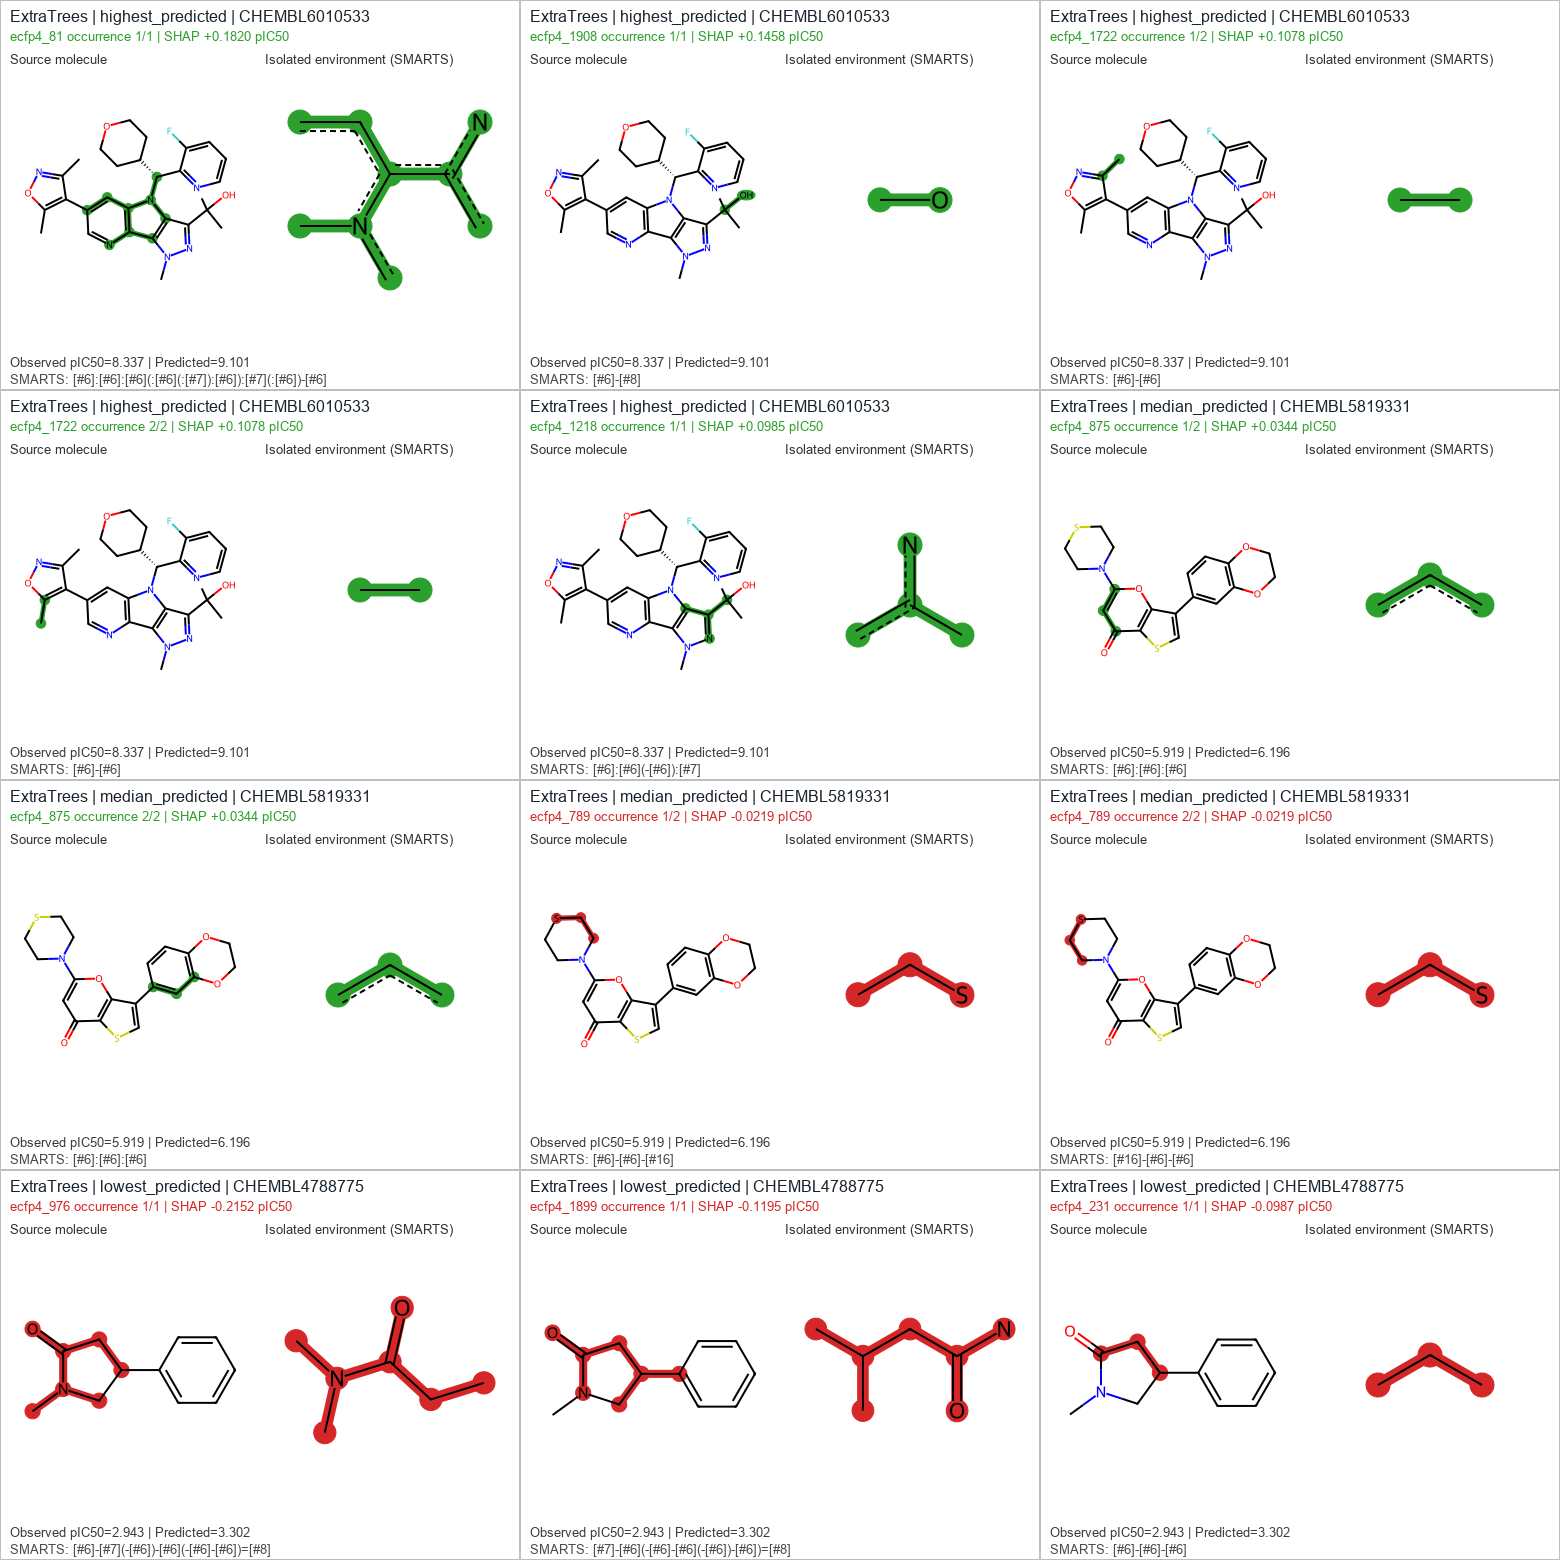

Contact sheet 2/2: morgan_substructure_contact_sheet_02.png


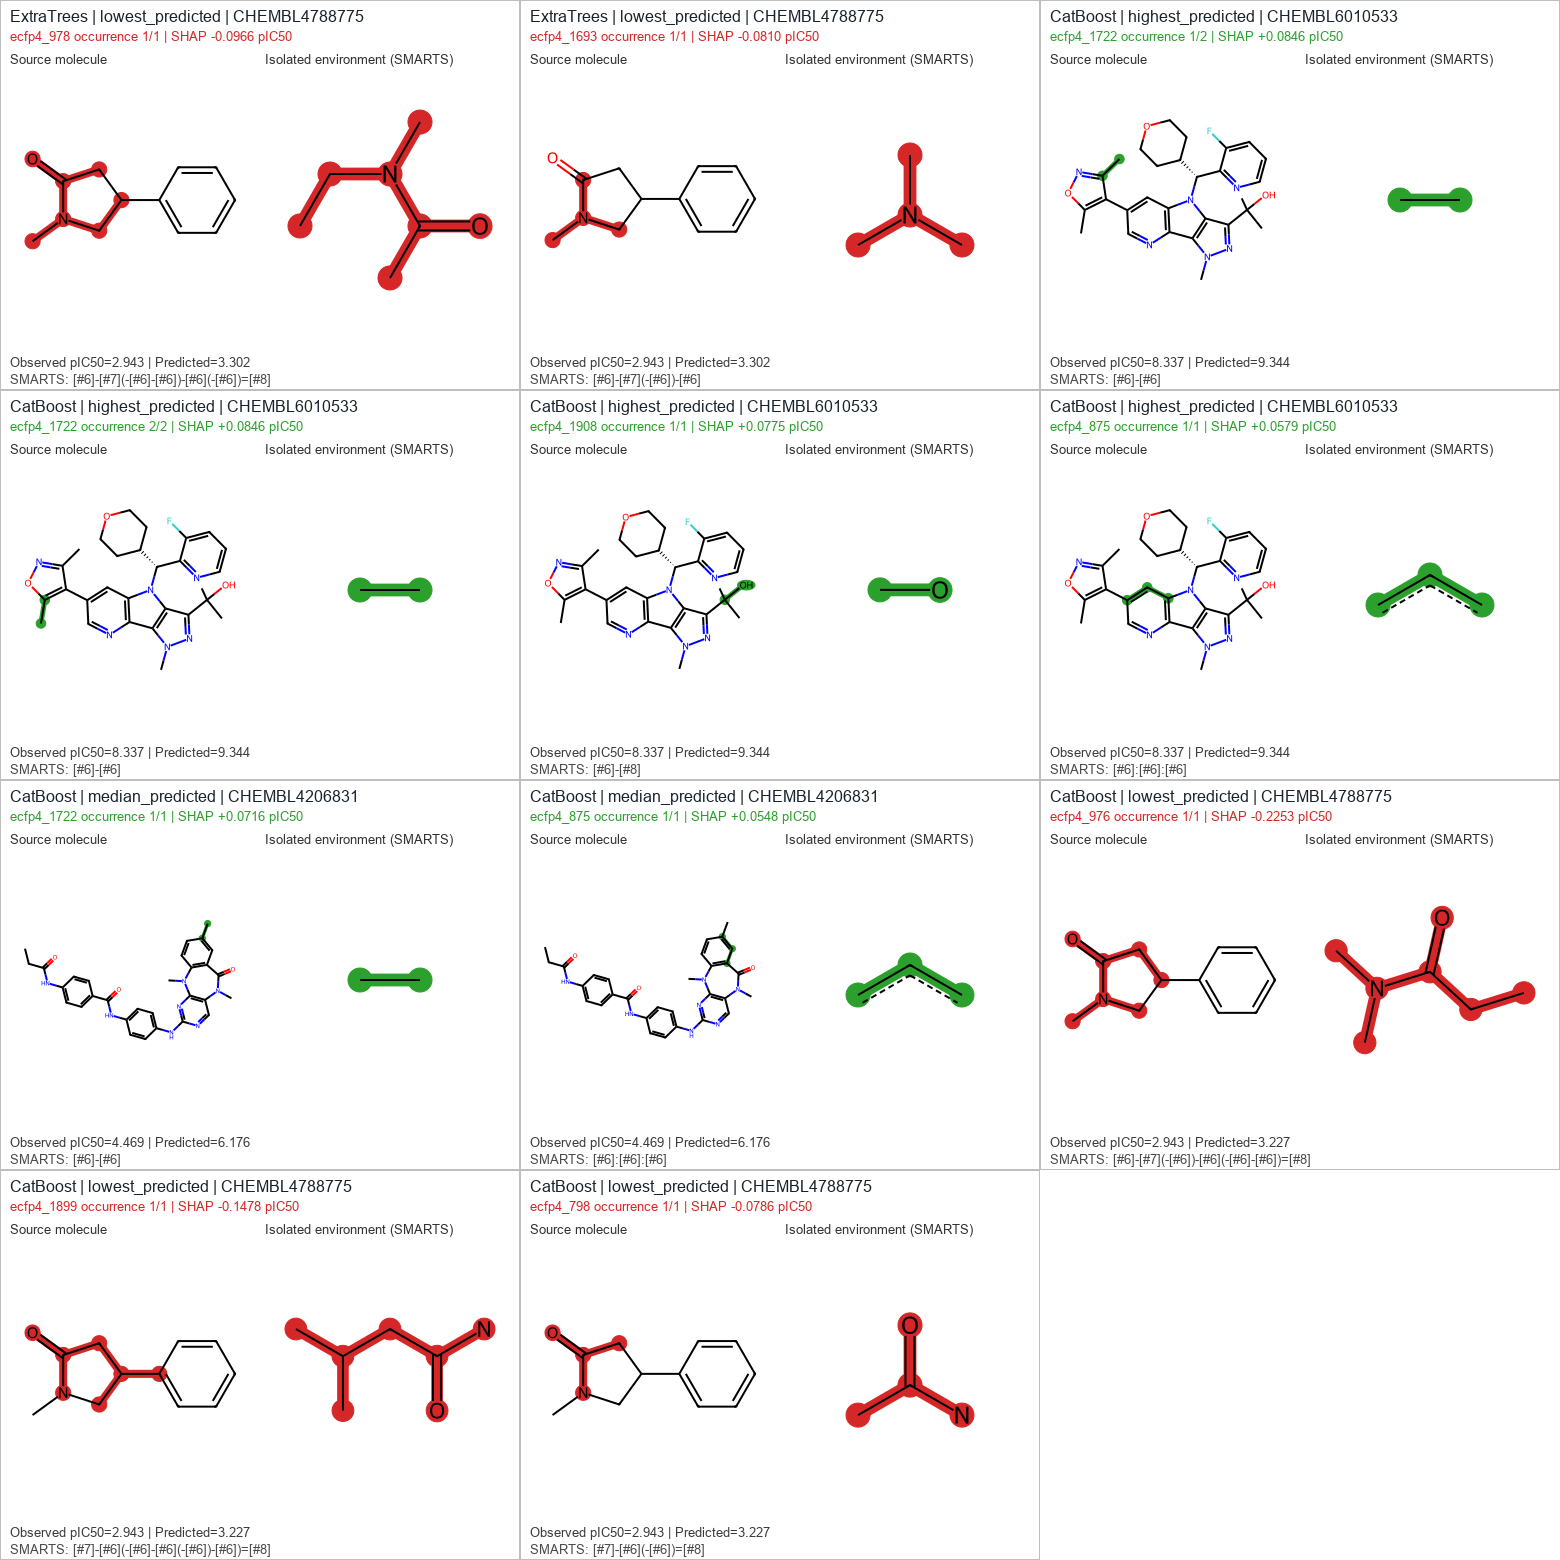

In [12]:
# 9d. Render every mapped occurrence: parent molecule + isolated Morgan environment
POSITIVE_COLOR = "#2ca02c"
NEGATIVE_COLOR = "#d62728"
RGB_BY_SIGN = {"positive": (44, 160, 44), "negative": (214, 39, 40)}
TILE_W, TILE_H = 520, 390
PANEL_W, PANEL_H = 250, 250

try:
    TILE_FONT = ImageFont.truetype("arial.ttf", 16)
    TILE_SMALL_FONT = ImageFont.truetype("arial.ttf", 13)
except OSError:
    try:
        TILE_FONT = ImageFont.truetype("DejaVuSans.ttf", 16)
        TILE_SMALL_FONT = ImageFont.truetype("DejaVuSans.ttf", 13)
    except OSError:
        TILE_FONT = ImageFont.load_default()
        TILE_SMALL_FONT = ImageFont.load_default()


def safe_image_stem(value):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_")


def hex_to_rdkit_rgb(hex_color):
    value = hex_color.lstrip("#")
    return tuple(int(value[i:i + 2], 16) / 255 for i in (0, 2, 4))


def parse_indices(text):
    """Parse a comma-separated index string; tolerate blanks and NaN (radius-0 environments have no bonds)."""
    return [int(x) for x in str(text).split(",") if x.strip() and x.strip().lower() != "nan"]


def draw_panel(mol, atom_ids, bond_ids, rd_color, fixed_bond_length=None):
    """Draw `mol` with the given atoms/bonds highlighted in one colour (Cairo; falls back to Draw.MolToImage)."""
    try:
        drawer = rdMolDraw2D.MolDraw2DCairo(PANEL_W, PANEL_H)
        opts = drawer.drawOptions()
        opts.padding = 0.08
        if fixed_bond_length:
            opts.fixedBondLength = fixed_bond_length
        drawer.DrawMolecule(
            mol, highlightAtoms=atom_ids, highlightBonds=bond_ids,
            highlightAtomColors={i: rd_color for i in atom_ids},
            highlightBondColors={i: rd_color for i in bond_ids},
        )
        drawer.FinishDrawing()
        return Image.open(BytesIO(drawer.GetDrawingText())).convert("RGB")
    except Exception:
        return Draw.MolToImage(
            mol, size=(PANEL_W, PANEL_H), highlightAtoms=atom_ids, highlightBonds=bond_ids,
            highlightColor=rd_color,
        ).convert("RGB")


def render_environment_tile(row):
    molecule = smarts_molecules[str(row["chembl_id"])]
    atom_ids = parse_indices(row["atom_indices_0based"])
    bond_ids = parse_indices(row["bond_indices_0based"])
    contribution = float(row["local_SHAP_contribution_pIC50"])
    sign = "positive" if contribution >= 0 else "negative"
    color_hex = POSITIVE_COLOR if contribution >= 0 else NEGATIVE_COLOR
    rd_color = hex_to_rdkit_rgb(color_hex)

    # Left panel: source molecule with the Morgan environment highlighted.
    parent_img = draw_panel(molecule, atom_ids, bond_ids, rd_color)

    # Right panel: the isolated environment, drawn from its SMARTS query. Query atoms are always
    # drawable, whereas a cut through an aromatic ring often cannot be sanitized as a standalone
    # SMILES. Unlabeled vertices are carbon; dashed lines are aromatic bonds.
    fragment_error = None
    try:
        with rdBase.BlockLogs():
            query = Chem.MolFromSmarts(str(row["SMARTS"]))
        if query is None:
            raise ValueError("SMARTS did not parse.")
        rdDepictor.Compute2DCoords(query)
        fragment_img = draw_panel(query, list(range(query.GetNumAtoms())),
                                  list(range(query.GetNumBonds())), rd_color, fixed_bond_length=40)
    except Exception as exc:
        fragment_error = f"{type(exc).__name__}: {exc}"
        fragment_img = Image.new("RGB", (PANEL_W, PANEL_H), "white")
        fallback_draw = ImageDraw.Draw(fragment_img)
        fallback_draw.text((10, PANEL_H // 2 - 18), "Fragment depiction unavailable", fill=(120, 30, 30), font=TILE_SMALL_FONT)
        fallback_draw.text((10, PANEL_H // 2 + 5), str(fragment_error)[:55], fill=(90, 90, 90), font=TILE_SMALL_FONT)

    tile = Image.new("RGB", (TILE_W, TILE_H), "white")
    draw = ImageDraw.Draw(tile)
    draw.rectangle((0, 0, TILE_W - 1, TILE_H - 1), outline=(190, 190, 190), width=1)
    model_label = str(row["model"]).replace("Regressor", "")
    title = f"{model_label} | {row['case']} | {row['chembl_id']}"
    subtitle = (f"{row['bit_feature']} occurrence {int(row['occurrence_in_molecule'])}/{int(row['n_occurrences_of_bit'])}"
                f" | SHAP {contribution:+.4f} pIC50")
    draw.text((10, 7), title, fill=(25, 35, 45), font=TILE_FONT)
    draw.text((10, 29), subtitle, fill=RGB_BY_SIGN[sign], font=TILE_SMALL_FONT)
    draw.text((10, 52), "Source molecule", fill=(50, 50, 50), font=TILE_SMALL_FONT)
    draw.text((TILE_W // 2 + 5, 52), "Isolated environment (SMARTS)", fill=(50, 50, 50), font=TILE_SMALL_FONT)
    tile.paste(parent_img, (5, 75))
    tile.paste(fragment_img, (TILE_W // 2 + 5, 75))
    draw.text((10, TILE_H - 35),
              f"Observed pIC50={float(row['observed_pIC50']):.3f} | Predicted={float(row['predicted_pIC50']):.3f}",
              fill=(60, 60, 60), font=TILE_SMALL_FONT)
    draw.text((10, TILE_H - 18), f"SMARTS: {str(row['SMARTS'])[:90]}", fill=(75, 75, 75), font=TILE_SMALL_FONT)
    return tile, sign, str(row["fragment_SMILES"]), fragment_error


image_records, tiles = [], []
for row_number, (_, row) in enumerate(environments.iterrows()):
    stem = "_".join([
        safe_image_stem(row["model"]), safe_image_stem(row["case"]), safe_image_stem(row["chembl_id"]),
        f"bit{int(row['bit_id'])}", f"occ{int(row['occurrence_in_molecule']):02d}",
    ])
    tile, sign, fragment_smiles_draw, fragment_error = render_environment_tile(row)
    image_path = ENV_IMAGE_DIR / f"{stem}.png"
    tile.save(image_path, format="PNG", dpi=(300, 300))
    tiles.append(tile)
    image_records.append({
        "environment_row": int(row_number), "model": row["model"], "case": row["case"],
        "chembl_id": row["chembl_id"], "bit_feature": row["bit_feature"],
        "occurrence_in_molecule": int(row["occurrence_in_molecule"]),
        "local_SHAP_contribution_pIC50": float(row["local_SHAP_contribution_pIC50"]),
        "contribution_direction": sign,
        "highlight_color": POSITIVE_COLOR if sign == "positive" else NEGATIVE_COLOR,
        "fragment_SMILES_source_table": row["fragment_SMILES"],
        "fragment_SMILES_for_depiction": fragment_smiles_draw,
        "fragment_depiction_source": "SMARTS query",
        "fragment_depiction_error": fragment_error or "",
        "SMARTS": row["SMARTS"], "image_path": str(image_path),
    })

image_index = pd.DataFrame(image_records)
image_index_path = SMARTS_TABLE_DIR / "local_shap_morgan_substructure_image_index.csv"
image_index.to_csv(image_index_path, index=False)

# Link the image files back to their SMARTS/environment rows (same row order).
environments = environments.copy()
environments["substructure_image_path"] = image_index["image_path"].to_numpy()
environments["contribution_direction"] = image_index["contribution_direction"].to_numpy()
environments.to_csv(SMARTS_TABLE_DIR / "local_shap_morgan_environment_smarts.csv", index=False)

# Contact sheets, 12 tiles each for readable labels.
SHEET_COLUMNS, TILES_PER_SHEET = 3, 12
contact_paths = []
for page_start in range(0, len(tiles), TILES_PER_SHEET):
    page = tiles[page_start:page_start + TILES_PER_SHEET]
    rows_in_page = (len(page) + SHEET_COLUMNS - 1) // SHEET_COLUMNS
    sheet = Image.new("RGB", (SHEET_COLUMNS * TILE_W, rows_in_page * TILE_H), "white")
    for local_i, tile in enumerate(page):
        sheet.paste(tile, ((local_i % SHEET_COLUMNS) * TILE_W, (local_i // SHEET_COLUMNS) * TILE_H))
    sheet_path = CONTACT_DIR / f"morgan_substructure_contact_sheet_{page_start // TILES_PER_SHEET + 1:02d}.png"
    sheet.save(sheet_path, format="PNG", dpi=(300, 300))
    contact_paths.append(sheet_path)

print(f"Rendered {len(tiles)} individual SHAP-mapped environments.")
print("Green = positive local SHAP contribution; red = negative local SHAP contribution.")
print("Individual parent + fragment PNGs:", ENV_IMAGE_DIR)
print("Image index:", image_index_path)
for sheet_number, sheet_path in enumerate(contact_paths, start=1):
    print(f"Contact sheet {sheet_number}/{len(contact_paths)}: {sheet_path.name}")
    display(IPyImage(filename=str(sheet_path)))

ExtraTreesRegressor | highest_predicted | CHEMBL6010533 | ecfp4_81
SMARTS: [#6]:[#6]:[#6](:[#6](:[#7]):[#6]):[#7](:[#6])-[#6]
Bit SHAP contribution (pIC50): 0.1819895424207339


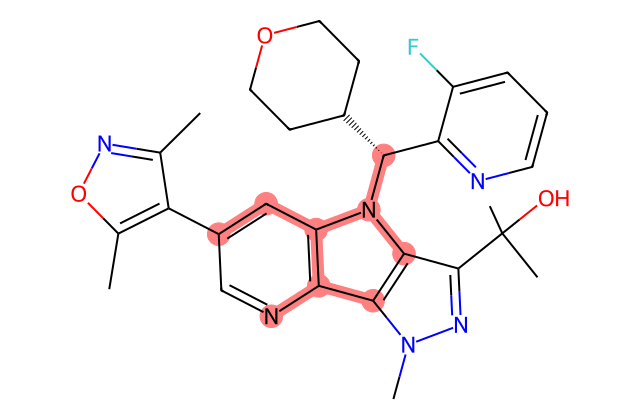

In [13]:
# 9d (optional). Visual check of one SMARTS environment: set PREVIEW_ROW to any row of `environments`
PREVIEW_ROW = 0
row = environments.iloc[PREVIEW_ROW]
mol = smarts_molecules[row["chembl_id"]]
highlight_atoms = parse_indices(row["atom_indices_0based"])
highlight_bonds = parse_indices(row["bond_indices_0based"])

print(f"{row['model']} | {row['case']} | {row['chembl_id']} | {row['bit_feature']}")
print("SMARTS:", row["SMARTS"])
print("Bit SHAP contribution (pIC50):", row["local_SHAP_contribution_pIC50"])
display(Draw.MolToImage(mol, size=(640, 420), highlightAtoms=highlight_atoms, highlightBonds=highlight_bonds))

### 9e. SMARTS and motif summaries for every locked-test molecule

This reuses the SHAP matrices from Section 3 (no recomputation) to map every present Morgan bit of every locked-test molecule to its occurrence-specific environment. Outputs: a complete molecule-by-bit SHAP table, the all-molecule SMARTS table (same columns as the representative-case table), a per-molecule summary, a bit-level summary, and recurring motifs ranked by mean signed SHAP.

When an environment cut crosses a stereogenic double bond whose defining atoms are outside the fragment, serialization retries without that fragment-level stereo annotation; this is recorded in `SMARTS_stereo_fallback` and `SMARTS_generation_note`. A repeated bit in one molecule shares one model-level SHAP value, so motif summaries count each molecule once per motif while occurrence rows are kept separately for structure mapping. Images are not rendered for every occurrence; image paths are filled only for the representative cases rendered in 9d.

In [14]:
# 9e. Occurrence-specific SMARTS and motif summaries for ALL locked-test molecules
MIN_MOTIF_MOLECULES = 5

bit_features = []
for feature in selected_features:
    match = re.fullmatch(r"ecfp4_(\d+)", feature)
    if match:
        bit_features.append((feature, int(match.group(1))))
if not bit_features:
    raise ValueError("No Morgan fingerprint columns were recognized among the fixed features (expected e.g. ecfp4_361).")
bit_cols = [f for f, _ in bit_features]
bit_id_by_feature = dict(bit_features)

test_list = test_index.tolist()
observed = (predictions.loc[predictions.model == MODELS[0]]
            .drop_duplicates("chembl_id").set_index("chembl_id").observed_pIC50.reindex(test_index))
X_bits = X_test[bit_cols].copy()
X_bits.index.name = "chembl_id"
X_bit_matrix = X_bits.to_numpy(dtype=float)

# ---- structure mapping (model-independent): present bits -> atom/bond environments -> SMARTS
structure_records, mismatch_rows, failure_rows = [], [], []
for i, cid in enumerate(test_list):
    mol = Chem.MolFromSmiles(smiles_by_id[cid])
    if mol is None:
        mismatch_rows.append({"chembl_id": cid, "feature": "", "reason": "Invalid standardized SMILES"})
        continue
    additional = rdFingerprintGenerator.AdditionalOutput()
    additional.AllocateBitInfoMap()
    fingerprint = MORGAN.GetFingerprint(mol, additionalOutput=additional)
    on_bits = set(map(int, fingerprint.GetOnBits()))
    bit_info = additional.GetBitInfoMap()

    for (feature, bit_id), value in zip(bit_features, X_bit_matrix[i]):
        matrix_present = value >= 0.5
        structure_present = bit_id in on_bits
        if matrix_present != structure_present:
            mismatch_rows.append({
                "chembl_id": cid, "feature": feature,
                "reason": f"feature_matrix_present={matrix_present}; standardized_structure_present={structure_present}"})
        if not (matrix_present and structure_present):
            continue

        occurrences = bit_info.get(bit_id, ())
        for occurrence_no, (center_atom_idx, radius) in enumerate(occurrences, start=1):
            atom_ids, bond_ids = environment_indices(mol, center_atom_idx, radius)
            try:
                smarts, fragment_kekule, stereo_note = fragment_strings_with_stereo_fallback(mol, atom_ids, bond_ids)
            except RuntimeError as exc:
                failure_rows.append({"chembl_id": cid, "feature": feature,
                                     "occurrence_in_molecule": occurrence_no, "reason": str(exc)[:300]})
                continue
            with rdBase.BlockLogs():
                query = Chem.MolFromSmarts(smarts)
            query_parses = query is not None
            n_matches = len(mol.GetSubstructMatches(query, uniquify=True)) if query_parses else 0
            structure_records.append({
                "chembl_id": cid, "bit_feature": feature, "bit_id": bit_id,
                "occurrence_in_molecule": occurrence_no, "n_occurrences_of_bit": len(occurrences),
                "center_atom_index_0based": int(center_atom_idx), "radius": int(radius),
                "atom_indices_0based": ",".join(map(str, atom_ids)),
                "bond_indices_0based": ",".join(map(str, bond_ids)),
                "fragment_SMILES": fragment_kekule, "SMARTS": smarts,
                "SMARTS_stereo_fallback": stereo_note != "stereo_preserved",
                "SMARTS_generation_note": stereo_note,
                "SMARTS_parses": bool(query_parses),
                "SMARTS_matches_in_source_molecule": int(n_matches),
                "source_canonical_SMILES": smiles_by_id[cid],
                "feature": feature, "feature_value": float(X_test.at[cid, feature]),
            })

structure_df = pd.DataFrame(structure_records)
if structure_df.empty:
    raise RuntimeError("No present Morgan environments were mapped for the locked test set.")

# ---- attach each model's local SHAP value and prediction to the structure records
env_frames = []
for model_name in MODELS:
    shap_frame = shap_by_model[model_name]
    frame = structure_df.copy()
    row_pos = shap_frame.index.get_indexer(frame["chembl_id"])
    col_pos = shap_frame.columns.get_indexer(frame["feature"])
    frame["local_SHAP_contribution_pIC50"] = shap_frame.to_numpy()[row_pos, col_pos]
    frame.insert(0, "model", model_name)
    frame["predicted_pIC50"] = frame["chembl_id"].map(pred_by_model[model_name])
    frame["observed_pIC50"] = frame["chembl_id"].map(observed)
    frame["contribution_direction"] = np.where(frame["local_SHAP_contribution_pIC50"] >= 0, "positive", "negative")
    env_frames.append(frame)
environments_all = pd.concat(env_frames, ignore_index=True)
environments_all["substructure_image_path"] = ""
environments_all["environment_SMARTS"] = environments_all["SMARTS"]
environments_all["fragment_SMILES_kekule"] = environments_all["fragment_SMILES"]

# Link the representative-case images rendered in 9d.
link_keys = ["model", "chembl_id", "bit_feature", "occurrence_in_molecule"]
image_lookup = image_index.drop_duplicates(link_keys).set_index(link_keys)["image_path"]
env_keys = pd.MultiIndex.from_frame(environments_all[link_keys])
environments_all["substructure_image_path"] = image_lookup.reindex(env_keys).fillna("").to_numpy()

environment_columns = [
    "model", "chembl_id", "predicted_pIC50", "observed_pIC50", "bit_feature", "bit_id",
    "local_SHAP_contribution_pIC50", "occurrence_in_molecule", "n_occurrences_of_bit",
    "center_atom_index_0based", "radius", "atom_indices_0based", "bond_indices_0based",
    "fragment_SMILES", "SMARTS", "SMARTS_stereo_fallback", "SMARTS_generation_note", "SMARTS_parses",
    "SMARTS_matches_in_source_molecule", "source_canonical_SMILES", "substructure_image_path",
    "contribution_direction", "feature", "feature_value", "environment_SMARTS", "fragment_SMILES_kekule",
]
environments_all = environments_all[environment_columns]
environments_all.to_parquet(ALL_TEST_TABLE_DIR / "all_test_local_shap_morgan_environment_smarts.parquet", index=False)
environments_all.to_csv(ALL_TEST_TABLE_DIR / "all_test_local_shap_morgan_environment_smarts.csv.gz", index=False, compression="gzip")

# ---- complete molecule x Morgan-bit SHAP table (vectorised)
x_long = X_bits.copy()
x_long.columns.name = None
x_long = x_long.reset_index().melt(id_vars="chembl_id", var_name="feature", value_name="feature_value")
bit_frames = []
for model_name in MODELS:
    s_long = shap_by_model[model_name][bit_cols].copy()
    s_long.columns.name = None
    s_long = s_long.reset_index().melt(id_vars="chembl_id", var_name="feature",
                                       value_name="local_SHAP_contribution_pIC50")
    table = s_long.merge(x_long, on=["chembl_id", "feature"], how="left")
    table.insert(0, "model", model_name)
    table["bit_id"] = table["feature"].map(bit_id_by_feature)
    table["bit_present_in_model_input"] = table["feature_value"] >= 0.5
    table["predicted_pIC50"] = table["chembl_id"].map(pred_by_model[model_name])
    table["observed_pIC50"] = table["chembl_id"].map(observed)
    bit_frames.append(table[["model", "chembl_id", "feature", "bit_id", "feature_value",
                             "bit_present_in_model_input", "local_SHAP_contribution_pIC50",
                             "predicted_pIC50", "observed_pIC50"]])
all_bit_contributions = pd.concat(bit_frames, ignore_index=True)
all_bit_contributions.to_parquet(ALL_TEST_TABLE_DIR / "all_test_local_morgan_bit_contributions.parquet", index=False)
all_bit_contributions.to_csv(ALL_TEST_TABLE_DIR / "all_test_local_morgan_bit_contributions.csv.gz", index=False, compression="gzip")

# ---- per-molecule summary and image index
case_summary_all = (environments_all.groupby(["model", "chembl_id"], as_index=False)
    .agg(n_highlighted_bits=("bit_id", "nunique"), n_mapped_occurrences=("bit_id", "size"),
         SMARTS_queries=("SMARTS", lambda values: " || ".join(values.astype(str)))))
case_summary_all.to_csv(ALL_TEST_TABLE_DIR / "all_test_local_shap_morgan_smarts_molecule_summary.csv", index=False)

image_index_all = environments_all[[
    "model", "chembl_id", "bit_feature", "occurrence_in_molecule", "local_SHAP_contribution_pIC50",
    "contribution_direction", "fragment_SMILES", "SMARTS", "substructure_image_path"]].copy()
image_index_all.insert(0, "environment_row", np.arange(len(image_index_all)))
image_index_all["highlight_color"] = np.where(image_index_all["contribution_direction"].eq("positive"), "#2ca02c", "#d62728")
image_index_all["image_path"] = image_index_all["substructure_image_path"]
image_index_all.to_csv(ALL_TEST_TABLE_DIR / "all_test_local_shap_morgan_image_index.csv.gz", index=False, compression="gzip")

mismatch_df = pd.DataFrame(mismatch_rows, columns=["chembl_id", "feature", "reason"])
mismatch_df.to_csv(ALL_TEST_TABLE_DIR / "all_test_morgan_structure_feature_mismatches.csv", index=False)
failure_df = pd.DataFrame(failure_rows, columns=["chembl_id", "feature", "occurrence_in_molecule", "reason"])
failure_df.to_csv(ALL_TEST_TABLE_DIR / "all_test_smarts_serialization_failures.csv", index=False)

# ---- bit-level and motif-level summaries (one row per molecule x bit / motif, so repeats do not inflate counts)
present_bits = all_bit_contributions.loc[all_bit_contributions["bit_present_in_model_input"]].copy()
bit_summary = (present_bits.groupby(["model", "feature", "bit_id"], as_index=False)
    .agg(n_molecules_with_bit=("chembl_id", "nunique"),
         mean_SHAP_pIC50=("local_SHAP_contribution_pIC50", "mean"),
         median_SHAP_pIC50=("local_SHAP_contribution_pIC50", "median"),
         fraction_positive_SHAP=("local_SHAP_contribution_pIC50", lambda x: float((x > 0).mean())),
         mean_observed_pIC50=("observed_pIC50", "mean"),
         median_observed_pIC50=("observed_pIC50", "median"),
         mean_predicted_pIC50=("predicted_pIC50", "mean")))
bit_summary.to_csv(ALL_TEST_TABLE_DIR / "all_test_morgan_bit_summary.csv", index=False)

molecule_motifs = environments_all.drop_duplicates(["model", "chembl_id", "feature", "fragment_SMILES_kekule"]).copy()
motif_summary = (molecule_motifs.groupby(
        ["model", "feature", "bit_id", "fragment_SMILES_kekule", "environment_SMARTS"], dropna=False, as_index=False)
    .agg(n_molecules=("chembl_id", "nunique"),
         mean_SHAP_pIC50=("local_SHAP_contribution_pIC50", "mean"),
         median_SHAP_pIC50=("local_SHAP_contribution_pIC50", "median"),
         fraction_positive_SHAP=("local_SHAP_contribution_pIC50", lambda x: float((x > 0).mean())),
         mean_observed_pIC50=("observed_pIC50", "mean"),
         median_observed_pIC50=("observed_pIC50", "median"),
         mean_predicted_pIC50=("predicted_pIC50", "mean")))
motif_summary["SHAP_direction"] = np.where(motif_summary["mean_SHAP_pIC50"] >= 0, "positive", "negative")
motif_summary = motif_summary.sort_values(["model", "mean_SHAP_pIC50", "n_molecules"], ascending=[True, False, False])
motif_summary.to_csv(ALL_TEST_TABLE_DIR / "all_test_recurring_morgan_motif_summary.csv", index=False)
supported_motifs = motif_summary.loc[motif_summary["n_molecules"] >= MIN_MOTIF_MOLECULES].copy()
supported_motifs.to_csv(ALL_TEST_TABLE_DIR / "all_test_recurring_morgan_motifs_n_ge_5.csv", index=False)

print("All-test-set SMARTS outputs saved under:", ALL_TEST_TABLE_DIR)
print("Molecule-bit SHAP rows:", len(all_bit_contributions))
print("Mapped present-bit environment occurrences (both models):", len(environments_all))
print("Morgan/structure mismatches:", len(mismatch_df), "| SMARTS serialization failures:", len(failure_df))
print(f"Recurring molecule-level motifs (n >= {MIN_MOTIF_MOLECULES}):", len(supported_motifs))
show_cols = ["feature", "n_molecules", "mean_SHAP_pIC50", "fraction_positive_SHAP", "fragment_SMILES_kekule", "environment_SMARTS"]
for direction, ascending in (("positive", False), ("negative", True)):
    print(f"\nMost {direction} recurring motifs per model:")
    for model_name in MODELS:
        print("\n", model_name)
        display(supported_motifs.loc[supported_motifs["model"].eq(model_name)]
                .sort_values(["mean_SHAP_pIC50", "n_molecules"], ascending=[ascending, False])
                .head(10)[show_cols].round(4))
if len(mismatch_df):
    print("\nWarning: feature-matrix / Morgan-structure mismatches were saved for review. "
          "Do not interpret mapped motifs for those rows until resolved.")

All-test-set SMARTS outputs saved under: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\all_test_set_shap\tables
Molecule-bit SHAP rows: 264298
Mapped present-bit environment occurrences (both models): 41104
Morgan/structure mismatches: 0 | SMARTS serialization failures: 0
Recurring molecule-level motifs (n >= 5): 448

Most positive recurring motifs per model:

 ExtraTreesRegressor


,feature,n_molecules,mean_SHAP_pIC50,fraction_positive_SHAP,fragment_SMILES_kekule,environment_SMARTS
643,ecfp4_1164,287,0.3506,1.0,C:N:N,[#6]:[#7]:[#7]
1114,ecfp4_81,6,0.3379,1.0,C:C:C(:C(:C):N):N(C):C,[#6]:[#6]:[#6](:[#6](:[#7]):[#6]):[#7](:[#6])-...
1056,ecfp4_5,6,0.2375,1.0,CC(=O)N,[#6]-[#6](=[#8])-[#7]
1059,ecfp4_5,5,0.2042,1.0,CCS,[#6]-[#6]-[#16]
1027,ecfp4_379,16,0.1996,1.0,C:C(C(:C:N):C(:C):O):C,[#6]:[#6](-[#6](:[#6]:[#7]):[#6](:[#6]):[#8]):...
844,ecfp4_1688,12,0.1961,1.0,CN(C)CC(:C):N,[#6]-[#7](-[#6])-[#6]-[#6](:[#6]):[#7]
812,ecfp4_1658,54,0.1943,1.0,C:N:N:C(:C):N,[#6]:[#7]:[#7]:[#6](:[#6]):[#7]
1054,ecfp4_5,35,0.1914,1.0,CC(=O)N,[#6](-[#6])(=[#8])-[#7]
1028,ecfp4_379,8,0.1872,1.0,C:C(C(:C:N):C(:C):O):C,[#6]:[#6](:[#6](:[#6]:[#7])-[#6](:[#6]):[#6]):...
1057,ecfp4_5,16,0.1868,1.0,CC(=O)N,[#7]-[#6](=[#8])-[#6]



 CatBoostRegressor


,feature,n_molecules,mean_SHAP_pIC50,fraction_positive_SHAP,fragment_SMILES_kekule,environment_SMARTS
475,ecfp4_5,6,0.2845,1.0,CC(=O)N,[#6]-[#6](=[#8])-[#7]
478,ecfp4_5,5,0.2372,1.0,CCS,[#6]-[#6]-[#16]
476,ecfp4_5,16,0.2173,1.0,CC(=O)N,[#7]-[#6](=[#8])-[#6]
473,ecfp4_5,35,0.1928,1.0,CC(=O)N,[#6](-[#6])(=[#8])-[#7]
215,ecfp4_1624,13,0.1533,1.0,CNC(:N:C):C(C):C,[#6]-[#6](:[#6]):[#6](:[#7]:[#6])-[#7]-[#6]
1,ecfp4_1027,5,0.1391,1.0,C:C(:C)C,[#6]-[#6](:[#6]):[#6]
336,ecfp4_1797,5,0.1389,1.0,CN(C)C(=O)[C@@H](C)N,[#6]-[#7](-[#6](-[#6@H](-[#7])-[#6])=[#8])-[#6]
334,ecfp4_1797,29,0.1378,1.0,CC(:C):C:C(N):C,[#7]-[#6](:[#6]):[#6]:[#6](:[#6])-[#6]
332,ecfp4_1797,14,0.1309,1.0,CC(:C):C:C(N):C,[#6]-[#6](:[#6]:[#6](-[#7]):[#6]):[#6]
263,ecfp4_1688,12,0.1193,1.0,CN(C)CC(:C):N,[#6]-[#7](-[#6])-[#6]-[#6](:[#6]):[#7]



Most negative recurring motifs per model:

 ExtraTreesRegressor


,feature,n_molecules,mean_SHAP_pIC50,fraction_positive_SHAP,fragment_SMILES_kekule,environment_SMARTS
1022,ecfp4_361,314,-0.7866,0.0,C:C(:C)C,[#6]:[#6](:[#6])-[#6]
1026,ecfp4_361,5,-0.6091,0.0,CCCOC,[#6]-[#8]-[#6]-[#6]-[#6]
1150,ecfp4_976,5,-0.2990,0.0,CCC(=O)N(C)C,[#6]-[#6]-[#6](=[#8])-[#7](-[#6])-[#6]
1151,ecfp4_976,5,-0.2759,0.0,CCC(=O)N(C)C,[#6]-[#7](-[#6])-[#6](-[#6]-[#6])=[#8]
1010,ecfp4_318,149,-0.2646,0.0,CC(:N):N,[#7]:[#6](-[#6]):[#7]
660,ecfp4_1244,12,-0.2106,0.0,CN(C)CC(:C):N,[#6]-[#7](-[#6])-[#6]-[#6](:[#7]):[#6]
944,ecfp4_1899,5,-0.1809,0.0,CC(C)CC(=O)N,[#6]-[#6](-[#6]-[#6](=[#8])-[#7])-[#6]
945,ecfp4_1899,5,-0.1678,0.0,CC(C)CC(=O)N,[#7]-[#6](-[#6]-[#6](-[#6])-[#6])=[#8]
776,ecfp4_1589,14,-0.1447,0.0,CN(C)CCN,[#6]-[#7](-[#6]-[#6]-[#7])-[#6]
841,ecfp4_1687,13,-0.1322,0.0,C:N(:C)CCN,[#7]-[#6]-[#6]-[#7](:[#6]):[#6]



 CatBoostRegressor


,feature,n_molecules,mean_SHAP_pIC50,fraction_positive_SHAP,fragment_SMILES_kekule,environment_SMARTS
441,ecfp4_361,314,-0.3838,0.0,C:C(:C)C,[#6]:[#6](:[#6])-[#6]
79,ecfp4_1244,12,-0.3615,0.0,CN(C)CC(:C):N,[#6]-[#7](-[#6])-[#6]-[#6](:[#7]):[#6]
445,ecfp4_361,5,-0.2886,0.0,CCCOC,[#6]-[#8]-[#6]-[#6]-[#6]
569,ecfp4_976,5,-0.2604,0.0,CCC(=O)N(C)C,[#6]-[#6]-[#6](=[#8])-[#7](-[#6])-[#6]
570,ecfp4_976,5,-0.2366,0.0,CCC(=O)N(C)C,[#6]-[#7](-[#6])-[#6](-[#6]-[#6])=[#8]
429,ecfp4_318,149,-0.2230,0.0,CC(:N):N,[#7]:[#6](-[#6]):[#7]
116,ecfp4_1340,5,-0.2105,0.0,C:C(C):C:C(F):C,[#6]-[#6](:[#6]):[#6]:[#6](:[#6])-[#9]
364,ecfp4_1899,5,-0.1694,0.0,CC(C)CC(=O)N,[#7]-[#6](-[#6]-[#6](-[#6])-[#6])=[#8]
363,ecfp4_1899,5,-0.1500,0.0,CC(C)CC(=O)N,[#6]-[#6](-[#6]-[#6](=[#8])-[#7])-[#6]
86,ecfp4_1284,12,-0.1462,0.0,C:C(:N(:C(C):N)CC)C,[#6]-[#6]-[#7](:[#6](-[#6]):[#7]):[#6](:[#6])-...


Applicability-domain error by max Tanimoto similarity bin:


,model,similarity_bin,n,rmse,mae,bias_obs_minus_pred
0,ExtraTreesRegressor,0.0-0.3,5,1.3017,1.0970,-0.6041
1,ExtraTreesRegressor,0.3-0.4,10,0.7674,0.6451,-0.5541
2,ExtraTreesRegressor,0.4-0.5,29,1.0347,0.7772,-0.0570
3,ExtraTreesRegressor,0.5-0.6,84,0.7823,0.5826,-0.0450
4,ExtraTreesRegressor,0.6-0.7,263,0.6087,0.4353,-0.0088
5,ExtraTreesRegressor,0.7-1.0,892,0.5111,0.3548,-0.0154
6,CatBoostRegressor,0.0-0.3,5,1.3114,1.1192,-0.5788
7,CatBoostRegressor,0.3-0.4,10,0.7035,0.5550,-0.4465
8,CatBoostRegressor,0.4-0.5,29,1.0479,0.7622,-0.0478
9,CatBoostRegressor,0.5-0.6,84,0.7478,0.5600,-0.0148


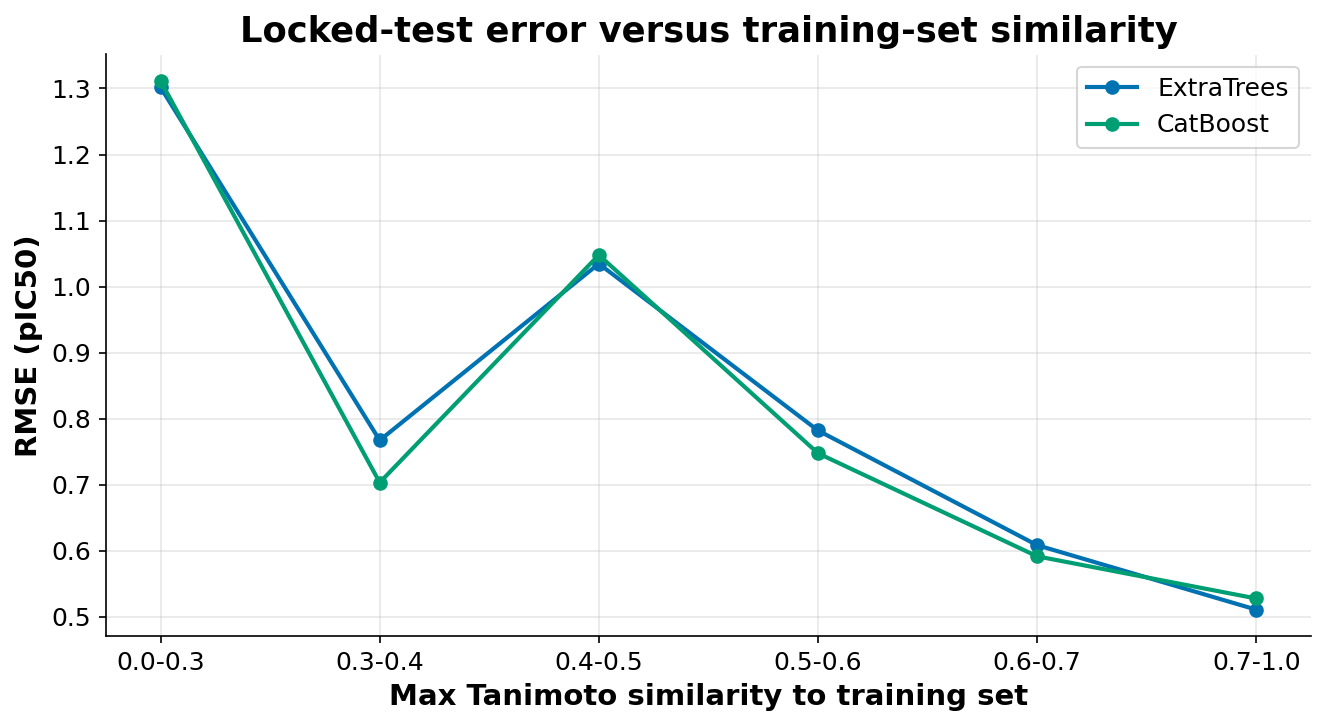

In [15]:
# 10. Error analysis by similarity to training set (from Stage 08)
ad = pd.read_csv(AD_FILE)
ad = ad[ad.model.isin(MODELS + ["Equal-weight ensemble (supplementary)"])].copy()

print("Applicability-domain error by max Tanimoto similarity bin:")
display(ad.round(4))

# Focused plot for the two models
ad_models = ad[ad.model.isin(MODELS)].copy()
fig, ax = plt.subplots(figsize=(9, 5))
for m, colour in zip(MODELS, ["#0072B2", "#009E73"]):
    sub = ad_models[ad_models.model == m]
    ax.plot(sub.similarity_bin, sub.rmse, marker="o", label=MODEL_SHORT[m], color=colour, linewidth=2)
ax.set_xlabel("Max Tanimoto similarity to training set")
ax.set_ylabel("RMSE (pIC50)")
ax.set_title("Locked-test error versus training-set similarity")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "error_by_similarity_both_models.png", dpi=600, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "error_by_similarity_both_models.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

ad_models.to_csv(TABLE_DIR / "error_by_similarity_both_models.csv", index=False)

In [16]:
# 11. Lightweight counterfactual-style explanations
# For a few high-interest molecules, show the most similar training molecules
# and contrast local SHAP profiles.

print("Building lightweight counterfactuals ...")

# Load training IDs and SMILES for similarity search
train_ids = pd.read_csv(TRAIN_IDS_FILE, dtype={"chembl_id": str})
train_ids["chembl_id"] = train_ids.chembl_id.astype(str)
train_smiles = smiles_by_id.reindex(train_ids.chembl_id).dropna()

def morgan_fp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return MORGAN.GetFingerprint(mol)

train_fps = []
train_ids_list = []
for cid, smi in train_smiles.items():
    fp = morgan_fp(smi)
    if fp is not None:
        train_fps.append(fp)
        train_ids_list.append(cid)

def most_similar_train(query_smiles, k=3):
    qfp = morgan_fp(query_smiles)
    if qfp is None:
        return []
    sims = DataStructs.BulkTanimotoSimilarity(qfp, train_fps)
    order = np.argsort(sims)[::-1][:k]
    return [(train_ids_list[i], float(sims[i])) for i in order]

# Choose a small set of interesting cases (2 low + 2 high per model)
counterfactual_cases = []
for model_name in MODELS:
    cases = cases_by_model[model_name]
    for group in ("lowest", "highest"):
        sub = cases[cases.group == group].head(2)
        counterfactual_cases.append(sub)
cf_cases = pd.concat(counterfactual_cases, ignore_index=True)

cf_rows = []
for _, row in cf_cases.iterrows():
    cid = row.chembl_id
    smi = smiles_by_id[cid]
    neighbours = most_similar_train(smi, k=3)
    for rank, (nid, sim) in enumerate(neighbours, start=1):
        cf_rows.append({
            "model": row.model,
            "query_chembl_id": cid,
            "query_group": row.group,
            "query_predicted_pIC50": row.predicted_pIC50,
            "query_actual_pIC50": row.actual_pIC50,
            "neighbour_rank": rank,
            "neighbour_chembl_id": nid,
            "tanimoto": sim,
            "neighbour_smiles": smiles_by_id.get(nid, ""),
        })

cf_table = pd.DataFrame(cf_rows)
cf_table.to_csv(TABLE_DIR / "counterfactual_nearest_neighbours.csv", index=False)
print(f"Counterfactual neighbour table written ({len(cf_table)} rows).")
display(cf_table.head(12).round(4))

print("\nNote: full side-by-side SHAP difference plots can be added later if needed;")
print("the neighbour list already supports manual inspection of structural changes.")

Building lightweight counterfactuals ...
Counterfactual neighbour table written (24 rows).


,model,query_chembl_id,query_group,query_predicted_pIC50,query_actual_pIC50,neighbour_rank,neighbour_chembl_id,tanimoto,neighbour_smiles
0,ExtraTreesRegressor,CHEMBL4788775,lowest,3.3021,2.9431,1,CHEMBL4778271,0.9259,CN1C[C@@H](c2ccccc2)CC1=O
1,ExtraTreesRegressor,CHEMBL4788775,lowest,3.3021,2.9431,2,CHEMBL4798352,0.8065,CN1CC(c2ccc(-c3ccccc3)cc2)CC1=O
2,ExtraTreesRegressor,CHEMBL4788775,lowest,3.3021,2.9431,3,CHEMBL4763778,0.6111,CN1CC(c2ccccc2-c2ccccc2)CC1=O
3,ExtraTreesRegressor,CHEMBL4764375,lowest,3.3021,2.8447,1,CHEMBL4778271,0.9259,CN1C[C@@H](c2ccccc2)CC1=O
4,ExtraTreesRegressor,CHEMBL4764375,lowest,3.3021,2.8447,2,CHEMBL4798352,0.7500,CN1CC(c2ccc(-c3ccccc3)cc2)CC1=O
5,ExtraTreesRegressor,CHEMBL4764375,lowest,3.3021,2.8447,3,CHEMBL4763778,0.6111,CN1CC(c2ccccc2-c2ccccc2)CC1=O
6,ExtraTreesRegressor,CHEMBL5184079,highest,8.6692,9.2297,1,CHEMBL5171591,0.6867,CCS(=O)(=O)Nc1ccc(Oc2ccc(F)cc2F)c(-c2cn(C)c(=O...
7,ExtraTreesRegressor,CHEMBL5184079,highest,8.6692,9.2297,2,CHEMBL5172345,0.6786,CCc1ncc(-c2cc3c(=O)n(C)cc(-c4cc(NS(=O)(=O)CC)c...
8,ExtraTreesRegressor,CHEMBL5184079,highest,8.6692,9.2297,3,CHEMBL5174374,0.6782,Cc1cc(-c2cc3c(=O)n(C)cc(-c4cc(NS(=O)(=O)C5CC5)...
9,ExtraTreesRegressor,CHEMBL5206375,highest,8.7615,9.3117,1,CHEMBL5205435,0.9487,CCS(=O)(=O)Nc1ccc(Oc2ccc(F)cc2F)c(-c2cn(C)c(=O...



Note: full side-by-side SHAP difference plots can be added later if needed;
the neighbour list already supports manual inspection of structural changes.


In [17]:
# 12. Final inventory, summary tables and manifest
print("=== Final summary ===\n")

print("Global importance – top 5 features per model:")
display(
    global_imp.groupby("model", sort=False)
    .head(5)[["model", "feature", "mean_abs_shap", "family"]]
    .reset_index(drop=True)
    .round(4)
)

print("\nSelected case counts:")
display(all_cases.groupby(["model", "group"]).size().unstack(fill_value=0))

print(f"\nMolecular highlight figures: {len(list(MOL_DIR.glob('*.png')))} PNG + {len(list(MOL_DIR.glob('*.svg')))} SVG")
print(f"Tables written to: {TABLE_DIR}")
print(f"Figures written to: {FIGURE_DIR}")

# File inventory
all_files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.json")
inventory = pd.DataFrame([
    {"file": str(p.relative_to(OUT_DIR)), "size_kB": round(p.stat().st_size / 1024, 1)}
    for p in all_files
])
inventory.to_csv(TABLE_DIR / "output_inventory.csv", index=False)
display(inventory)

write_manifest(
    "10_interpretation",
    {
        "models": MODELS,
        "feature_set": "exact fixed 250 Stage 05 features",
        "shap_source": "recomputed (TreeSHAP) from the current fitted Stage 08 models; verified against Stage 08 predictions and SHAP additivity",
        "smarts_mapping": "occurrence-specific Morgan-environment SMARTS for representative cases (highest / median / lowest predicted) and for all locked-test molecules",
        "case_selection": "10 lowest + 10 median-centered + 10 highest predicted pIC50 per model; prediction only",
        "observed_activity_use": "display and table labelling only",
        "morgan_mapping": "environment-aware; radius-2 substructures recorded; overlap resolved by strongest |SHAP|",
        "pharmacophore_grouping": "chemical class labels derived from actual atom environments of high-SHAP bits",
        "error_analysis": "Stage 08 applicability-domain tables by max Tanimoto similarity",
        "counterfactuals": "3 nearest training neighbours (Tanimoto) for a small set of low/high cases",
        "figure_dpi": 600,
        "no_imputation": True,
        "no_reselection": True,
        "svr_excluded": True,
    },
    inputs=[
        SELECTED_FILE, TEST_IDS_FILE, TRAIN_IDS_FILE, CLEANED_FILE,
        FEATURES_FILE, PREDICTIONS_FILE, AD_FILE,
    ] + list(MODEL_FILES.values()),
    outputs=all_files,
)

print("\nStage 10 interpretation notebook complete.")
print(f"All outputs under: {OUT_DIR}")

=== Final summary ===

Global importance – top 5 features per model:


,model,feature,mean_abs_shap,family
0,ExtraTreesRegressor,ecfp4_361,0.2895,Morgan
1,ExtraTreesRegressor,ecfp4_1164,0.1387,Morgan
2,ExtraTreesRegressor,ecfp4_1722,0.0760,Morgan
3,ExtraTreesRegressor,ecfp4_318,0.0684,Morgan
4,ExtraTreesRegressor,ecfp4_875,0.0484,Morgan
5,CatBoostRegressor,ecfp4_361,0.1686,Morgan
6,CatBoostRegressor,ecfp4_1722,0.0758,Morgan
7,CatBoostRegressor,mordred2d_SpMax_A,0.0737,Mordred 2D
8,CatBoostRegressor,ecfp4_875,0.0642,Morgan
9,CatBoostRegressor,ecfp4_318,0.0563,Morgan



Selected case counts:


group,highest,lowest,middle
model,,,
CatBoostRegressor,10,10,10
ExtraTreesRegressor,10,10,10



Molecular highlight figures: 60 PNG + 60 SVG
Tables written to: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\tables
Figures written to: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\figures


,file,size_kB
0,all_test_set_shap\tables\all_test_local_morgan...,7217.9
1,all_test_set_shap\tables\all_test_local_morgan...,2987.9
2,all_test_set_shap\tables\all_test_local_shap_m...,1295.6
3,all_test_set_shap\tables\all_test_local_shap_m...,908.2
4,all_test_set_shap\tables\all_test_local_shap_m...,692.0
...,...,...
175,tables\smarts\local_shap_absent_top_bits_not_m...,2.1
176,tables\smarts\local_shap_morgan_environment_sm...,10.2
177,tables\smarts\local_shap_morgan_smarts_case_su...,0.9
178,tables\smarts\local_shap_morgan_substructure_i...,7.4



Stage 10 interpretation notebook complete.
All outputs under: C:\Users\USER\Documents\E\Code\outputs\10_interpretation


## How to read the results

- **Global importance**: mean |SHAP| rankings and family contributions (Morgan vs Mordred 2D) for ExtraTrees and CatBoost.
- **Selected cases**: 10 lowest, 10 median-centred and 10 highest predicted molecules per model. Selection used predicted pIC50 only; observed values are shown for reference.
- **Molecular highlights**: each high-SHAP Morgan bit receives its own colour. The legend reports bit number, signed SHAP, number of mapped environments, and the chemical classes of those environments. Overlapping atoms/bonds are coloured by the bit with the largest absolute SHAP.
- **Pharmacophore-style grouping**: environment classes (aromatic, aliphatic, H-bond donor/acceptor, halogen, polar, …) are derived directly from the radius-2 substructures that set the high-SHAP bits. The summary shows which classes predominate among positive versus negative contributions.
- **Error by similarity**: locked-test RMSE as a function of maximum Tanimoto similarity to the training set (from Stage 08).
- **Counterfactuals**: for a small number of low- and high-prediction molecules the three nearest training neighbours (Tanimoto) are listed so structural differences can be inspected.

All figures are saved at 600 dpi (PNG) and as SVG. The notebook does not refit models, reselect features, or use test activity for ranking.
- **SHAP provenance**: Section 3 recomputes TreeSHAP from the current Stage-08 models and records the model-file hash, the maximum difference from the Stage-08 predictions and the SHAP additivity gap in `shap_values/shap_provenance.csv`.
- **SMARTS for highlighted Morgan environments** (Section 9): for the highest, median and lowest predicted test molecule of each model, every present top-|SHAP| Morgan bit is converted into occurrence-specific SMARTS and rendered (green = positive, red = negative); the same mapping is saved for all locked-test molecules with recurring-motif summaries (`all_test_set_shap/tables/`).